# Application of MobileNetV2 to Waste Classification

**Paper yang direproduksi:** Yong, L., Ma, L., Sun, D., & Du, L. (2023). *Application of MobileNetV2 to waste classification.* PLOS ONE, 18(3), e0282336. <https://doi.org/10.1371/journal.pone.0282336>

**Notebook reproduksi sumber:** `Reproduce Code/Output_Reproduce_MobileNetV2_Waste_Classification.ipynb`

**Tim:** Kelompok 16, Internship Lab KC

**Tanggal submission:** 30 Oktober 2026

Notebook ini adalah laporan akhir yang ditulis dari notebook reproduksi. Semua angka berasal dari eksekumen notebook tersebut: training MobileNetV2 dan CNN baseline, evaluasi test, serta analisis error. Laporan ini tidak menambah eksperimen baru, hanya menyajikan kembali hasil yang sudah ada dengan struktur penulisan laporan.

## Daftar isi

1. [Abstrak](#bab-1)
2. [Pendahuluan dan pertanyaan penelitian](#bab-2)
3. [Penelitian terkait dan rancangan alur penelitian](#bab-3)
4. [Dependensi dan reproduksibilitas](#bab-4)
5. [Data dan exploratory data analysis](#bab-5)
6. [Preprocessing dan feature engineering](#bab-6)
7. [Baseline](#bab-7)
8. [Metode yang digunakan](#bab-8)
9. [Validasi dan evaluasi](#bab-9)
10. [Hasil eksperimen dan analisis](#bab-10)
11. [Analisis error](#bab-11)
12. [Biaya komputasi](#bab-12)
13. [Model final dan inferensi](#bab-13)
14. [Pembahasan](#bab-14)
15. [Keterbatasan](#bab-15)
16. [Kesimpulan](#bab-16)
17. [Referensi](#bab-17)

<a id="bab-1"></a>
## 1. Abstrak

Pengelompokan sampah otomatis dibutuhkan agar sampah rumah tangga bisa dipilah sesuai jenisnya sebelum dibuang. Paper Yong et al. (2023) memakai MobileNetV2 untuk mengklasifikasikan sampah ke dalam 4 kategori besar yang dipecah menjadi 245 subkategori, dan melaporkan akurasi test 82,92% dengan cross-entropy loss 1,621. Karena dataset asli paper tidak tersedia, reproduksi ini memakai dataset publik Kaggle `alistairking/recyclable-and-household-waste-classification` berisi 30 fine class pada dua source group (`default` dan `real_world`), lalu memetakan 30 kelas itu ke 3 major class: Kitchen waste, Recyclable waste, dan Other waste.

Pipeline training mengikuti kode sumber paper: MobileNetV2 pretrained ImageNet di-fine-tune penuh dengan SGD, learning rate 0,001, momentum 0,9, dan StepLR step 7 gamma 0,1 selama 50 epoch dengan batch size 42. CNN dua-lapis dari `train_cnn.py` dipakai sebagai baseline. Evaluasi utama mengikuti `test_model.py`: test accuracy, cross-entropy loss, dan classification report per major class. MobileNetV2 mencapai akurasi test 85,17% dengan loss 0,4653, sedangkan CNN hanya 40,07% dengan loss 4,3413. Pada level 3 major class, MobileNetV2 mencapai 96,20% dengan macro F1 0,9489. Selisih 45,10 poin akurasi itu disertai jumlah parameter 10,57× lebih kecil pada MobileNetV2.

<a id="bab-2"></a>
## 2. Pendahuluan dan pertanyaan penelitian

### Latar belakang

Sampah rumah tangga yang tercampur memaksa orang menebak cara membuangnya, dan sampah yang salah tempat akan mengotori material hasil recovery. Klasifikasi waste adalah subdomain computer vision yang masuk akal untuk diotomatisasi: gambar sampah bisa dibaca sebelum dibuang, dan hasilnya dipakai sebagai keputusan awal, bukan pengganti fasilitas sorting.

Paper yang direproduksi menyebut empat kategori besar: kitchen waste, recyclable waste, hazardous waste, dan other waste, masing-masing dipecah menjadi subkategori hingga 245 kelas. Turunannya berupa WeChat applet dengan back-end Flask dan desktop window PyQt5. Reproduksi ini berhenti pada model computer vision, karena yang dinilai dalam laporan adalah model dan evaluasinya, bukan antarmuka aplikasi.

### Tantangan dataset

Tiga tantangan menentukan desain eksperimen.

Pertama, dataset asli paper tidak tersedia dalam bentuk yang bisa dipakai. Repositori kode sumber menyertakan dataset kecil berisi 477 file, sedangkan paper menyebut sekitar 80.000 gambar. Dataset Kaggle 30 kelas dipakai sebagai pengganti, dan perbedaan ini harus dibaca bersama hasil, bukan disembunyikan.

Kedua, dataset Kaggle mengandung banyak duplikat. Dari 15.000 file, 3.737 file merupakan duplikat persis berdasarkan hash MD5, dan sebagian duplikat muncul di kelas berbeda. Duplikat yang lolos ke split membuat akurasi test terlihat lebih baik dari kemampuan model yang sebenarnya.

Ketiga, granularitas label naik dari 4 kategori menjadi 30 fine class. Salah pada level fine class tidak selalu berarti salah pada level major class, jadi kedua tingkat akurasi perlu dilaporkan.

### Tujuan dan pertanyaan penelitian

- **RQ1:** Seberapa baik MobileNetV2 yang di-fine-tune penuh dapat mengklasifikasikan 30 fine class sampah pada dataset pengganti?
- **RQ2:** Berapa selisih performa terhadap CNN baseline yang dilatih dari nol dengan arsitektur sama seperti paper?
- **RQ3:** Pada level major class, apakah kesalahan fine class masih bermakna secara kategorikal?
- **RQ4:** Apakah pretrained weight dan jumlah parameter yang lebih sedikit menjelaskan mengapa MobileNetV2 menang telak?

<a id="bab-3"></a>
## 3. Penelitian terkait dan rancangan alur penelitian

### 3.1 Penelitian terkait

**Yong et al. (2023), PLOS ONE.** Paper yang direproduksi. Menggabungkan fine-tuning MobileNetV2 dengan dataset 245 subkategori, membandingkannya dengan CNN konvolusional, lalu hasil evaluasinya dikirim ke applet WeChat. Metrik yang dipakai: test accuracy dan cross-entropy loss, masing-masing 82,92% dan 1,621 untuk MobileNetV2 serta 67,50% dan 4,075 untuk CNN. Relevansinya bagi laporan ini ada pada protocol evaluasi dan pada pilihan dua model pembanding.

**Repositori kode sumber paper.** Berisi `train_245_class.py` (PyTorch), `train_cnn.py` dan `train_mobilenet.py` (Keras), `test_model.py` (evaluasi), serta `utils.py` (pembagian data 8:1:1). README menyebut akurasi test sekitar 82%. Kode ini dipakai sebagai rujukan konfigurasi training dan sebagai bentuk laporan evaluasi yang di notebook reproduksi disebut *GitHub-style evaluation*.

**Dataset Kaggle `alistairking/recyclable-and-household-waste-classification`.** 30 folder kelas, masing-masing berisi subfolder `default` dan `real_world`. Dipakai sebagai dataset pengganti karena dataset paper tidak tersedia.

### 3.2 Rancangan alur penelitian

```mermaid
flowchart TD
    A[Dataset Kaggle 30 kelas] --> B[Manifest + MD5 dedupe]
    B --> C[Split 8:1:1 stratified per kelas dan source group]
    C --> D[Transform train: RandomResizedCrop + flip + ImageNet norm]
    C --> E[Transform eval: Resize 256 + CenterCrop 224]
    D --> F[MobileNetV2 fine-tune 50 epoch]
    E --> F
    D --> G[CNN baseline 30 epoch]
    E --> G
    F --> H[Checkpoint state_dict + metadata]
    G --> H
    H --> I[Test accuracy + cross-entropy loss]
    H --> J[Classification report 3 major class]
    H --> K[Error analysis dan confusion matrix]
```

Urutan ini sama dengan urutan cell notebook reproduksi: manifest dibuat dari seluruh file, dedupe MD5 dijalankan sebelum split, split menulis tiga CSV, kedua model dilatih pada loader yang sama dengan transform berbeda, dan evaluasi memakai split test yang tidak pernah disentuh selama training.

<a id="bab-4"></a>
## 4. Dependensi dan reproduksibilitas

### Environment

| Komponen | Server training | Evaluasi ulang lokal |
|---|---|---|
| Python | 3.12.3 | 3.14 |
| PyTorch | 2.15.0+cu132 | 2.9.1+cpu |
| torchvision | 0.29.2+cu132 | 0.24.1+cpu |
| NumPy | 2.5.4 | 2.5.1 |
| pandas | 3.1.0 | 3.0.5 |
| Device | GPU (`cuda`) | CPU |
| Seed | 42 | 42 |

Training dijalankan di server GPU. Laporan ini mengevaluasi ulang checkpoint di CPU, dan hasilnya cocok dengan metrik server sampai digit keempat, seperti yang terlihat pada cell evaluasi di bagian 9. Angka yang dipakai di seluruh laporan tetap memakai nilai dari server training.

### Aturan reproducibility

`seed_everything` mengunci Python, NumPy, dan PyTorch, menyalakan `torch.backends.cudnn.deterministic`, dan mematikan `benchmark`. Split ditulis ke manifest CSV, bukan ke folder file, sehingga pembagian data bisa diperiksa ulang tanpa menyalin gambar. Setiap checkpoint menyimpan state dict bersama metadata: epoch terbaik, akurasi validation, nama kelas, daftar major class, dan peta `class_to_major`.

### Struktur folder

```text
checkpoint_1/
├── Datasets/images/images/<class>/{default,real_world}/*.png
├── Reproduce Code/Output_Reproduce_MobileNetV2_Waste_Classification.ipynb
├── Report & Presentation/Final Report - Kelompok 16.ipynb
├── Source Code/                 # kode sumber paper
├── outputs/
│   ├── figures/                 # 14 grafik
│   ├── models/                  # 4 file .pt
│   ├── results/                 # 17 file metrik
│   └── splits/                  # manifest split
└── Paper/journal.pone.0282336.pdf
```

### Cara menjalankan

Notebook reproduksi dijalankan dari folder `Reproduce Code/`. Path dataset diambil dari variabel lingkungan `TRASH_DATA_DIR`, atau dari unduhan Kaggle bila `ALLOW_KAGGLE_DOWNLOAD` aktif. Notebook laporan ini hanya membaca artefak training: checkpoint, history, dan file metrik.

### Tempat kode: konfigurasi laporan

Cell berikut menyiapkan path, seed, dan device, lalu memuat manifest split dan definisi kelas.

In [1]:
from __future__ import annotations

import hashlib
import json
import math
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torchvision import models, transforms
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score,
)

ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.unicode_minus": False})


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "outputs").is_dir() and (candidate / "Datasets").is_dir():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd().resolve())
DATA_ROOT = Path(
    os.environ.get("TRASH_DATA_DIR", REPO_ROOT / "Datasets" / "images" / "images")
).resolve()
OUTPUT_DIR = REPO_ROOT / "outputs"
RESULT_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE_STR = "cuda" if torch.cuda.is_available() else "cpu"

print(f"repo root   : {REPO_ROOT}")
print(f"data root   : {DATA_ROOT} (exists={DATA_ROOT.exists()})")
print(f"device      : {DEVICE_STR}")
print(f"python      : {os.sys.version.split()[0]}")
print(f"torch       : {torch.__version__}")

repo root   : /home/noctican/Coolyeah/Lab/KC/checkpoint_1
data root   : /home/noctican/Coolyeah/Lab/KC/checkpoint_1/Datasets/images/images (exists=True)
device      : cpu
python      : 3.14.8
torch       : 2.9.1+cpu


In [2]:
CLASS_NAMES = [
    "aerosol_cans",
    "aluminum_food_cans",
    "aluminum_soda_cans",
    "cardboard_boxes",
    "cardboard_packaging",
    "clothing",
    "coffee_grounds",
    "disposable_plastic_cutlery",
    "eggshells",
    "food_waste",
    "glass_beverage_bottles",
    "glass_cosmetic_containers",
    "glass_food_jars",
    "magazines",
    "newspaper",
    "office_paper",
    "paper_cups",
    "plastic_cup_lids",
    "plastic_detergent_bottles",
    "plastic_food_containers",
    "plastic_shopping_bags",
    "plastic_soda_bottles",
    "plastic_straws",
    "plastic_trash_bags",
    "plastic_water_bottles",
    "shoes",
    "steel_food_cans",
    "styrofoam_cups",
    "styrofoam_food_containers",
    "tea_bags",
]

MAJOR_NAMES = ["Kitchen waste", "Recyclable waste", "Other waste"]

CLASS_TO_MAJOR = {
    "coffee_grounds": "Kitchen waste",
    "eggshells": "Kitchen waste",
    "food_waste": "Kitchen waste",
    "tea_bags": "Kitchen waste",
    "aerosol_cans": "Recyclable waste",
    "aluminum_food_cans": "Recyclable waste",
    "aluminum_soda_cans": "Recyclable waste",
    "cardboard_boxes": "Recyclable waste",
    "cardboard_packaging": "Recyclable waste",
    "clothing": "Recyclable waste",
    "glass_beverage_bottles": "Recyclable waste",
    "glass_cosmetic_containers": "Recyclable waste",
    "glass_food_jars": "Recyclable waste",
    "magazines": "Recyclable waste",
    "newspaper": "Recyclable waste",
    "office_paper": "Recyclable waste",
    "paper_cups": "Recyclable waste",
    "plastic_detergent_bottles": "Recyclable waste",
    "plastic_food_containers": "Recyclable waste",
    "plastic_shopping_bags": "Recyclable waste",
    "plastic_soda_bottles": "Recyclable waste",
    "plastic_water_bottles": "Recyclable waste",
    "shoes": "Recyclable waste",
    "steel_food_cans": "Recyclable waste",
    "disposable_plastic_cutlery": "Other waste",
    "plastic_cup_lids": "Other waste",
    "plastic_straws": "Other waste",
    "plastic_trash_bags": "Other waste",
    "styrofoam_cups": "Other waste",
    "styrofoam_food_containers": "Other waste",
}

CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
MAJOR_TO_IDX = {name: i for i, name in enumerate(MAJOR_NAMES)}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
IMG_SIZE = 224

all_df = pd.read_csv(OUTPUT_DIR / "splits" / "all.csv")
train_df = all_df[all_df["split"] == "train"].reset_index(drop=True)
val_df = all_df[all_df["split"] == "val"].reset_index(drop=True)
test_df = all_df[all_df["split"] == "test"].reset_index(drop=True)

print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")
print(f"major class: {MAJOR_NAMES}")
print(f"test major distribution: {test_df['class_name'].map(CLASS_TO_MAJOR).value_counts().to_dict()}")

train 9,006 | val 1,124 | test 1,133
major class: ['Kitchen waste', 'Recyclable waste', 'Other waste']
test major distribution: {'Recyclable waste': 767, 'Other waste': 219, 'Kitchen waste': 147}


<a id="bab-5"></a>
## 5. Data dan exploratory data analysis

### 5.1 Deskripsi dataset

Dataset pengganti berasal dari Kaggle, `alistairking/recyclable-and-household-waste-classification`. Strukturnya 30 folder kelas, masing-masing berisi dua subfolder:

```text
images/images/
├── aerosol_cans/
│   ├── default/*.png
│   └── real_world/*.png
├── aluminum_food_cans/
...
└── tea_bags/
```

Jumlah file per kelas bervariasi: 264 sampai 491 gambar, rata-rata 375,43 dan median 364,5 per kelas. Rasio kelas terbesar terhadap terkecil 1,86, jadi distribusinya cukup seimbang dan tidak butuh class weighting. Dua source group dipisah karena `real_world` berisi foto sampah di surroundings nyata, sedangkan `default` berisi foto dengan latar yang lebih bersih.

Split dibuat stratified per pasangan `(class_name, source_group)`, jadi setiap kelas dan setiap source group hadir di ketiga split. Manifest disimpan sebagai CSV dengan kolom `abs_path`, `rel_path`, `class_name`, `source_group`, `md5`, `split`, dan `label`.

| Split | Jumlah | Proporsi |
|---|---:|---:|
| Train | 9.006 | 79,96% |
| Validation | 1.124 | 9,98% |
| Test | 1.133 | 10,06% |
| **Total** | **11.263** | **100%** |

### Tempat kode: manifest, dedupe, dan split

Cell berikut membaca manifest yang sudah ditulis notebook reproduksi dan memverifikasi invariant split: tidak ada path duplikat, tidak ada MD5 yang muncul di dua split, dan setiap kelas serta setiap source group ada di semua split.

In [3]:
manifest = pd.read_csv(OUTPUT_DIR / "splits" / "all.csv")
manifest["major_class"] = manifest["class_name"].map(CLASS_TO_MAJOR)

print(f"total images      : {len(manifest):,}")
print(f"unique md5        : {manifest['md5'].nunique():,}")
print(f"classes           : {manifest['class_name'].nunique()}")
print()
print(manifest["split"].value_counts().reindex(["train", "val", "test"]).to_string())
print()
print("images per source group:")
print(manifest["source_group"].value_counts().to_string())

# Leakage and coverage checks.
assert manifest["rel_path"].duplicated().sum() == 0, "duplicate path in manifest"
assert manifest["md5"].duplicated().sum() == 0, "duplicate md5 in manifest"
assert manifest.groupby("md5")["split"].nunique().max() == 1, "md5 leaked across splits"
assert manifest.groupby("split")["class_name"].nunique().eq(30).all(), "missing class in a split"
assert manifest.groupby("split")["source_group"].nunique().eq(2).all(), "missing source group in a split"
print()
print("OK: no duplicate path, no duplicate md5, no cross-split leakage, full class coverage")

total images      : 11,263
unique md5        : 11,263
classes           : 30

split
train    9006
val      1124
test     1133

images per source group:
source_group
default       7019
real_world    4244

OK: no duplicate path, no duplicate md5, no cross-split leakage, full class coverage


**Interpretasi.** Dedupe MD5 berjalan sebelum split, bukan sesudahnya, sehingga tidak ada gambar identik yang bisa muncul di train dan test sekaligus. Split yang proporsinya mendekati 8:1:1 dan stratified per pasangan kelas dan source group membuat setiap kelas terwakili di test, sehingga accuracy per kelas bisa dihitung tanpa kelas kosong.

### 5.2 Distribusi kelas dan source group

Cell berikut menampilkan jumlah gambar per kelas dan per source group.

,Value
files before dedupe,15000.00
unique images,11263.00
duplicates removed,3737.00
unique md5,11263.00
classes,30.00
min images per class,264.00
max images per class,491.00
mean images per class,375.43
median images per class,364.50
max/min ratio,1.86


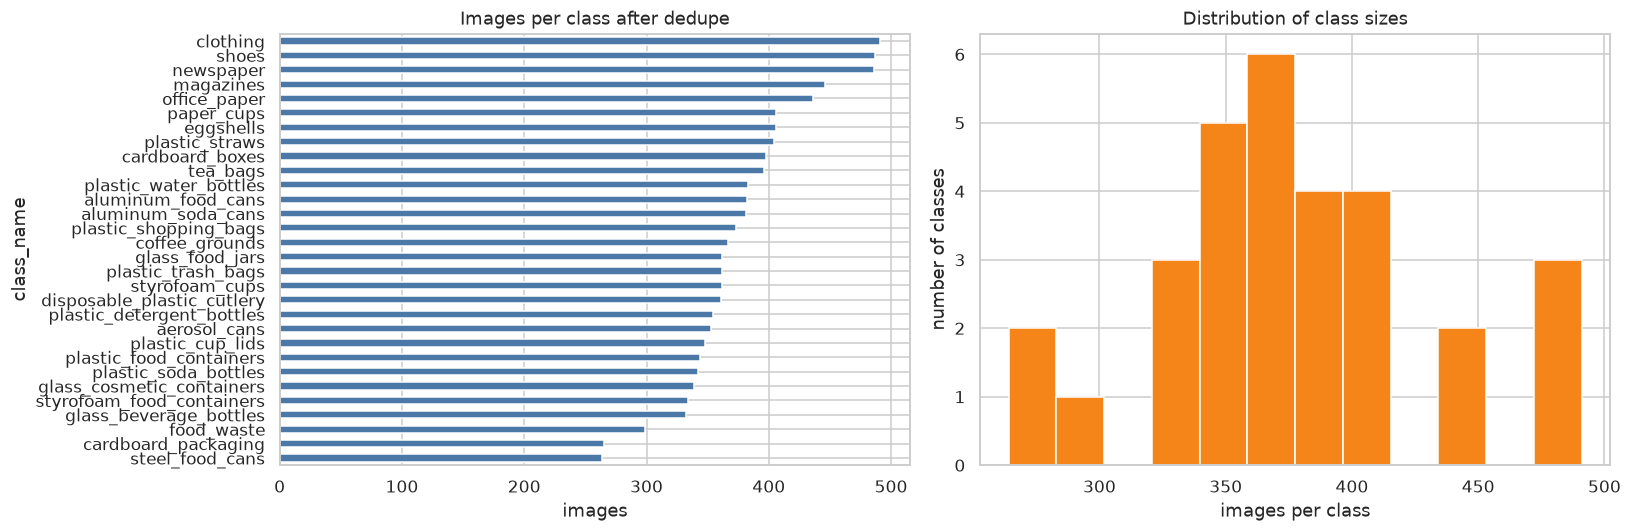

In [4]:
class_counts = manifest.groupby("class_name").size().reindex(CLASS_NAMES)
source_counts = manifest.groupby("source_group").size()

eda_summary = pd.DataFrame({
    "Value": [
        15000,
        len(manifest),
        3737,
        manifest["md5"].nunique(),
        manifest["class_name"].nunique(),
        int(class_counts.min()),
        int(class_counts.max()),
        round(float(class_counts.mean()), 2),
        float(class_counts.median()),
        round(float(class_counts.max() / class_counts.min()), 2),
        int(source_counts.get("default", 0)),
        int(source_counts.get("real_world", 0)),
    ],
}, index=[
    "files before dedupe",
    "unique images",
    "duplicates removed",
    "unique md5",
    "classes",
    "min images per class",
    "max images per class",
    "mean images per class",
    "median images per class",
    "max/min ratio",
    "default images",
    "real_world images",
])
display(eda_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
class_counts.sort_values().plot(kind="barh", ax=axes[0], color="#4C78A8")
axes[0].set_title("Images per class after dedupe")
axes[0].set_xlabel("images")
axes[1].hist(class_counts.values, bins=12, color="#F58518", edgecolor="white")
axes[1].set_title("Distribution of class sizes")
axes[1].set_xlabel("images per class")
axes[1].set_ylabel("number of classes")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_eda_class_balance.png", bbox_inches="tight")
plt.show()
plt.close(fig)

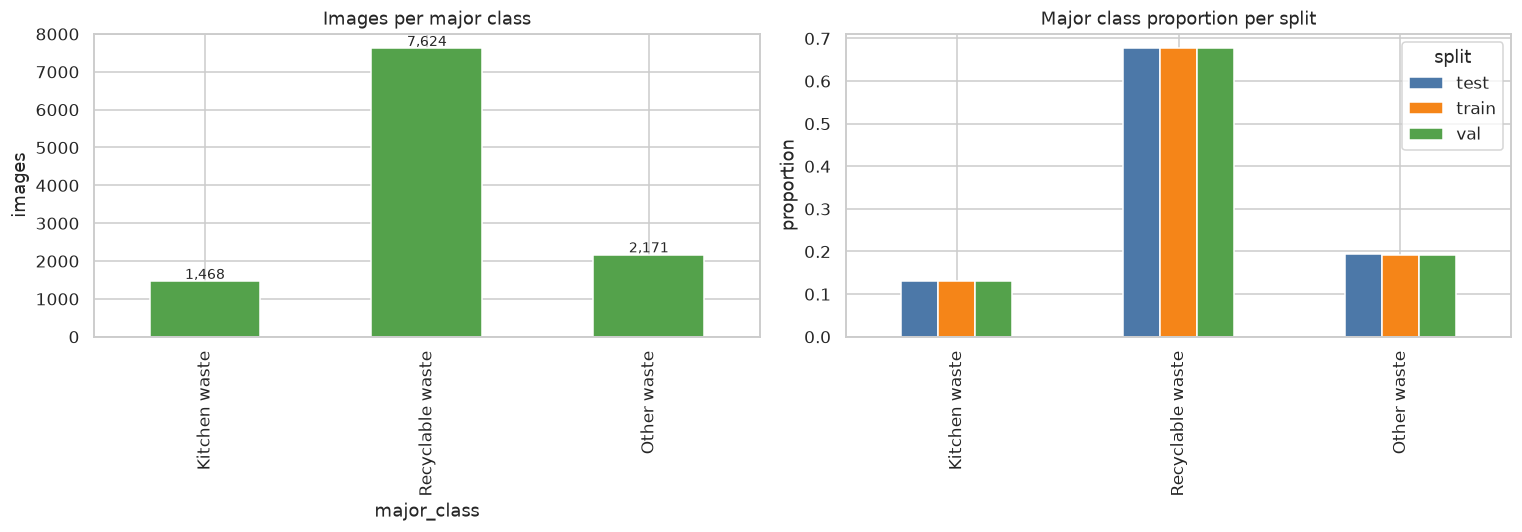

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
major_counts = manifest["major_class"].value_counts().reindex(MAJOR_NAMES)
major_counts.plot(kind="bar", ax=axes[0], color="#54A24B")
axes[0].set_title("Images per major class")
axes[0].set_ylabel("images")
for i, v in enumerate(major_counts):
    axes[0].text(i, v + 60, f"{v:,}", ha="center", fontsize=9)

pd.crosstab(manifest["major_class"], manifest["split"], normalize="columns").reindex(MAJOR_NAMES).plot(
    kind="bar", ax=axes[1], color=["#4C78A8", "#F58518", "#54A24B"]
)
axes[1].set_title("Major class proportion per split")
axes[1].set_ylabel("proportion")
axes[1].set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_major_distribution.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Interpretasi.** Recyclable waste menyumbang 67,7% dataset karena 20 dari 30 kelas termasuk kategori itu, sedangkan Kitchen waste hanya 4 kelas (12,97%) dan Other waste 6 kelas (19,33%). Proporsi tiap major class hampir identik di ketiga split, jadi pergeseran distribusi label antar split tidak terjadi. Ketidakseimbangan jumlah kelas ada di level major class, dan ini yang membuat macro F1 pada classification report penting dibaca, bukan hanya accuracy.

### 5.3 Kualitas data: duplikasi dan missing value

Duplikasi ditangani di atas lewat hash MD5. Dua hal lain diperiksa: apakah ada file yang tidak bisa dibaca, dan apakah label kelas konsisten dengan isi folder.

### Tempat kode: pemeriksaan kualitas data

In [6]:
from PIL import Image

broken = []
for rel in manifest["rel_path"].head(1000):
    path = DATA_ROOT / rel
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception as exc:  # noqa: BLE001
        broken.append((rel, str(exc)))

print("checked files        : 1000")
print(f"unreadable files     : {len(broken)}")

# Folder label must match the class the file lives in.
mismatched = manifest[~manifest.apply(
    lambda r: r["rel_path"].startswith(f"{r['class_name']}/"), axis=1
)]
print(f"label/folder mismatch: {len(mismatched)}")
assert len(broken) == 0, broken[:5]
assert len(mismatched) == 0
print("OK: images readable, labels consistent with folder structure")

checked files        : 1000
unreadable files     : 0
label/folder mismatch: 0
OK: images readable, labels consistent with folder structure


### 5.4 Karakteristik gambar

Pada sampel 800 gambar, seluruh gambar berukuran 256×256 dengan aspect ratio 1,0 dan tanpa variasi ukuran. Statistik brightness dan contrast dihitung dari sampel yang sama.

### Tempat kode: statistik gambar

,width,height,aspect_ratio,brightness,contrast
count,800.0,800.0,800.0,800.00,800.00
mean,256.0,256.0,1.0,185.92,60.31
std,0.0,0.0,0.0,39.15,22.63
min,256.0,256.0,1.0,43.77,10.03
25%,256.0,256.0,1.0,159.20,43.41
50%,256.0,256.0,1.0,189.73,61.07
75%,256.0,256.0,1.0,215.55,76.86
max,256.0,256.0,1.0,251.48,120.75


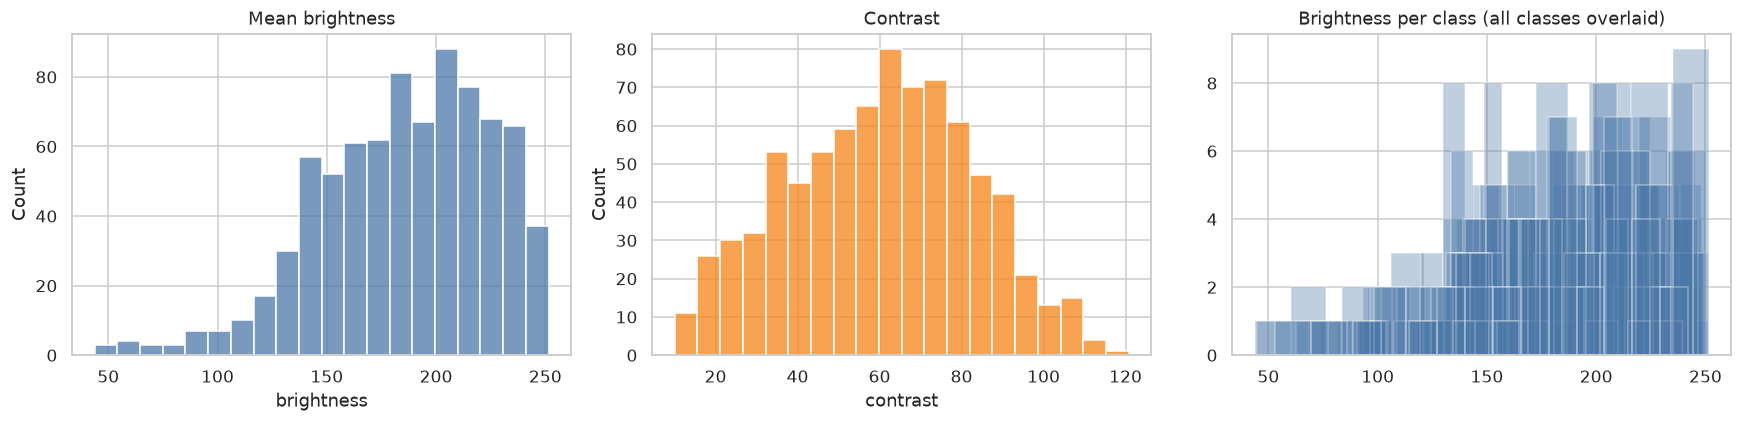

In [7]:
sample = manifest.sample(min(len(manifest), 800), random_state=SEED)
stats = []
for row in sample.itertuples():
    with Image.open(DATA_ROOT / row.rel_path) as img:
        rgb = img.convert("RGB")
        width, height = rgb.size
        gray = np.asarray(rgb.convert("L").resize((64, 64)), dtype=np.float32)
    stats.append({
        "class_name": row.class_name,
        "width": width,
        "height": height,
        "aspect_ratio": width / height,
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
    })
image_stats = pd.DataFrame(stats)
display(image_stats[["width", "height", "aspect_ratio", "brightness", "contrast"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(image_stats["brightness"], bins=20, ax=axes[0], color="#4C78A8")
axes[0].set_title("Mean brightness")
sns.histplot(image_stats["contrast"], bins=20, ax=axes[1], color="#F58518")
axes[1].set_title("Contrast")
for class_name, group in image_stats.groupby("class_name"):
    axes[2].hist(group["brightness"], bins=12, alpha=0.35, color="#4C78A8")
axes[2].set_title("Brightness per class (all classes overlaid)")
axes[2].set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_eda_image_stats.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Interpretasi.** Semua gambar berukuran sama, jadi tidak ada kebutuhan resize berbasis aspect ratio dan tidak ada padding putih yang perlu ditangani. Brightness rata-rata 185,99 dengan rentang 42,18 sampai 248,65 menunjukkan variasi pencahayaan yang cukup besar antar gambar, sebagian karena perbedaan source group. `coffee_grounds` (141,46) dan `magazines` (163,73) paling gelap, `plastic_detergent_bottles` (210,67) paling terang. Variasi ini yang membuat normalisasi ImageNet pada input penting, dan juga alasan `real_world` lebih sulit daripada `default`.

### 5.5 Distribusi train, validation, dan test

### Tempat kode: perbandingan source group antar split

In [8]:
group_split = pd.crosstab(manifest["split"], manifest["source_group"], normalize="index").reindex(
    ["train", "val", "test"]
)
display(group_split.round(4))

per_class_split = manifest.groupby(["class_name", "split"]).size().unstack(fill_value=0)
per_class_split = per_class_split.reindex(CLASS_NAMES)
per_class_split["train_share"] = per_class_split["train"] / per_class_split.sum(axis=1)
display(per_class_split[["train", "val", "test", "train_share"]].round(3))

source_group,default,real_world
split,,
train,0.6231,0.3769
val,0.6237,0.3763
test,0.6231,0.3769


split,train,val,test,train_share
class_name,,,,
aerosol_cans,282,35,36,0.799
aluminum_food_cans,305,38,39,0.798
aluminum_soda_cans,305,38,38,0.801
cardboard_boxes,319,40,39,0.802
cardboard_packaging,212,26,27,0.800
clothing,393,49,49,0.800
coffee_grounds,294,36,37,0.801
disposable_plastic_cutlery,289,36,36,0.801
eggshells,325,41,40,0.800


**Interpretasi.** Proporsi `default` dan `real_world` konsisten di ketiga split, sekitar 62% berbanding 38%. Proporsi train per kelas berada di rentang yang sempit, sehingga tidak ada kelas yang kehilangan porsi train-nya. Tidak ada indikasi distribution shift pada level source group maupun kelas. Yang berbeda adalah difficulty, bukan komposisi: akurasi model pada `real_world` lebih rendah daripada pada `default`, dan itu dilaporkan sebagai insight tambahan di bagian 10.

<a id="bab-6"></a>
## 6. Preprocessing dan feature engineering

Preprocessing mengikuti `train_245_class.py` untuk MobileNetV2 dan `train_cnn.py` untuk CNN baseline. Bedanya disengaja, bukan ketidaktelitian.

### MobileNetV2

```text
Train : RandomResizedCrop(224) → RandomHorizontalFlip() → ToTensor() → Normalize(ImageNet)
Eval  : Resize(256) → CenterCrop(224) → ToTensor() → Normalize(ImageNet)
```

Alasan tiap langkah. `RandomResizedCrop` menambah variasi posisi dan skala objek, yang dibutuhkan karena training set hanya 9.006 gambar untuk 30 kelas. `RandomHorizontalFlip` menambah variasi orientasi dengan asumsi objek sampah simetris kiri-kanan, yang memang berlaku untuk botol, kaleng, dan kemasan. `Normalize` memakai mean dan std ImageNet karena bobot pretrained dihitung dengan statistik tersebut; tanpa normalisasi, feature map awal model tidak berada di rentang yang diharapkan.

### CNN baseline

```text
Resize((224, 224)) → ToTensor()
```

CNN dilatih dari nol tanpa bobot pretrained, jadi normalisasi ImageNet tidak diperlukan. `ToTensor()` saja sudah memberi rentang 0 sampai 1, setara dengan `Rescaling(1/255)` pada kode Keras asli. Resize langsung ke 224×224 meniru apa yang dilakukan `train_cnn.py`, yang juga mengabaikan rasio aspek.

### Feature engineering

Tidak ada. Seluruh informasi berasal dari pixel RGB. Augmentasi pada training diperlakukan sebagai regularizer, dan feature engineering manual untuk gambar sampah di domain ini tidak pernah dieksplorasi di paper maupun kode sumber.

### Tempat kode: transform

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.029475987..1.1600001].


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.029475987..1.1600001].


eval tensor : (3, 224, 224) | mean 1.5419 | std 1.5773
cnn tensor  : (3, 224, 224) | min 0.0000 | max 1.0000
source image: (256, 256)


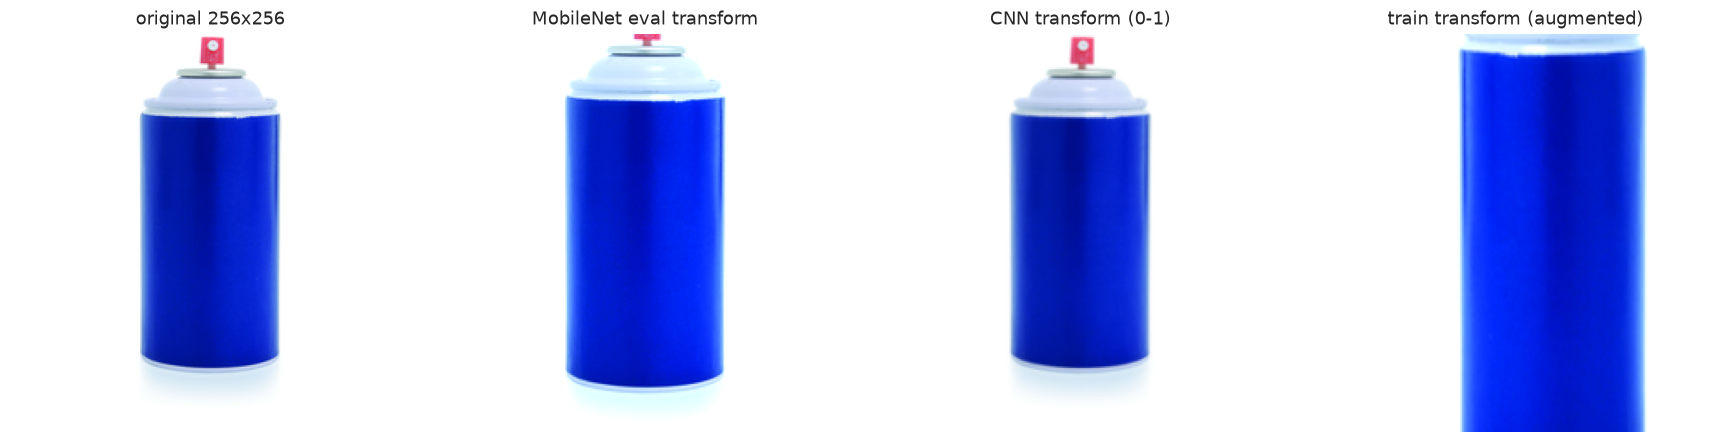

In [9]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

cnn_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# Sanity check: pipeline test harus menghasilkan tensor 3x224x224 dengan mean ~0.
sample_img = Image.open(DATA_ROOT / test_df["rel_path"].iloc[0]).convert("RGB")
t = eval_transform(sample_img)
c = cnn_transform(sample_img)
print(f"eval tensor : {tuple(t.shape)} | mean {t.mean():.4f} | std {t.std():.4f}")
print(f"cnn tensor  : {tuple(c.shape)} | min {c.min():.4f} | max {c.max():.4f}")
print(f"source image: {sample_img.size}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(sample_img)
axes[0].set_title("original 256x256")
axes[1].imshow(t.permute(1, 2, 0).numpy() * 0.25 + 0.5)
axes[1].set_title("MobileNet eval transform")
axes[2].imshow(c.permute(1, 2, 0).numpy())
axes[2].set_title("CNN transform (0-1)")
axes[3].imshow(train_transform(sample_img).permute(1, 2, 0).numpy() * 0.25 + 0.5)
axes[3].set_title("train transform (augmented)")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_preprocessing.png", bbox_inches="tight")
plt.show()
plt.close(fig)

<a id="bab-7"></a>
## 7. Baseline

### 7.1 Baseline yang dipakai

Baseline adalah CNN konvolusional dua-lapis dari `train_cnn.py`, dengan arsitektur yang sama seperti model pembanding di paper:

```text
Conv2D(32, 3x3) → ReLU → MaxPool(2x2)
Conv2D(64, 3x3) → ReLU → MaxPool(2x2)
Flatten → Dense(128, ReLU) → Dense(30, Softmax)
```

Alasan pemilihan. Baseline ini persis model yang dibandingkan di paper, jadi selisih performa mengukur kontribusi arsitektur MobileNetV2 dan bukan perbedaan setup. CNN dilatih dari nol dengan optimizer Adam learning rate 0,001, 30 epoch, batch size 16, tanpa scheduler.

### 7.2 Arsitektur MobileNetV2

`torchvision.models.mobilenet_v2` dengan bobot ImageNet, lalu `classifier[1]` diganti `Linear(1280, 30)`. Seluruh parameter di-fine-tune tanpa pembekuan backbone, sama seperti `train_245_class.py`. Arsitektur MobileNetV2 sendiri tersusun dari inverted residual block: expansion, depthwise convolution, dan projection, dengan shortcut connection.

Optimizer dan scheduler:

| Hyperparameter | MobileNetV2 | CNN |
|---|---|---|
| Optimizer | SGD | Adam |
| Learning rate | 0,001 | 0,001 |
| Momentum | 0,9 | - |
| Scheduler | StepLR(step 7, gamma 0,1) | tanpa |
| Epoch | 50 | 30 |
| Batch size | 42 | 16 |
| Loss | CrossEntropyLoss | CrossEntropyLoss |
| Pretrained | Ya (ImageNet) | Tidak |
| Parameter | 2.262.302 | 23.911.262 |

### Tempat kode: definisi model

In [10]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_mobilenet_v2(num_classes: int, pretrained: bool = False) -> nn.Module:
    model = models.mobilenet_v2(weights="DEFAULT" if pretrained else None)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model


class ClassicalCNN(nn.Module):
    '''Two-convolution CNN matching the paper's comparison model.'''

    def __init__(self, num_classes: int, in_shape=(3, 224, 224)):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        with torch.no_grad():
            flat_features = self.features(torch.zeros(1, *in_shape)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_features, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


mobilenet_eval = build_mobilenet_v2(30, pretrained=False)
cnn_eval = ClassicalCNN(30)

mn_params = count_parameters(mobilenet_eval)
cnn_params = count_parameters(cnn_eval)
print(f"MobileNetV2 parameters : {mn_params:,}")
print(f"CNN parameters         : {cnn_params:,}")
print(f"ratio                  : {cnn_params / mn_params:.2f}x")
print()
print("MobileNetV2 classifier head:")
print(mobilenet_eval.classifier)

MobileNetV2 parameters : 2,262,302
CNN parameters         : 23,911,262
ratio                  : 10.57x

MobileNetV2 classifier head:
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=30, bias=True)
)


**Interpretasi.** Parameter CNN 23.911.262, dan 99,90% di antaranya ada di satu layer `Linear(186624, 128)` hasil flatten. Model CNN padat ini punya kapasitas yang sangat besar untuk 30 kelas, tapi bobotnya dilatih dari nol dengan 9.006 gambar, jadi sebagian besar kapasitas itu tidak pernah terpakai dan berakhir sebagai overfitting. MobileNetV2 punya 2.262.302 parameter, 10,57× lebih sedikit, dan sebagian besar bobotnya sudah berisi representasi visual generik dari ImageNet. Ini hipotesis utama untuk menjelaskan selisih performa.

### 7.3 Hasil baseline

Hasil CNN lengkap ada di bagian 10. Ringkasnya: akurasi test 40,07%, cross-entropy loss 4,3413, top-3 accuracy 56,66%, dan akurasi 3 major class 72,02%. Akurasi validation terbaik terjadi di epoch 9 dengan 42,70%, sementara epoch 30 sudah overfit berat dengan train accuracy 97,48% dan validation accuracy 40,75%. Selisih 45,10 poin akurasi terhadap MobileNetV2 mengonfirmasi bahwa arsitektur pretrained-lah yang menentukan, bukan sekadar hyperparameters.

<a id="bab-8"></a>
## 8. Metode yang digunakan

Metode utama adalah fine-tuning penuh MobileNetV2 pada 30 fine class, lalu evaluasi dua tingkat: 30 fine class sebagai granularity utama, dan 3 major class sebagai granularity kategorikal yang lebih dekat ke tujuan aplikasi.

### 8.1 Fine-tuning MobileNetV2

Backbone MobileNetV2 pretrained dimuat dari torchvision, head classifier diganti menjadi layer linear 1280 ke 30, dan seluruh 2.262.302 parameter dilatih. Tidak ada tahap feature extraction yang membekukan backbone, karena `train_245_class.py` juga melakukan full fine-tuning.

Loss function adalah cross-entropy standar, sesuai task klasifikasi multiclass. Optimizer SGD dengan momentum 0,9, learning rate 0,001, dan StepLR dengan step_size 7 serta gamma 0,1. Scheduler dipanggil setelah phase train pada setiap epoch, dan learning rate turun 10× setiap 7 epoch. Pada epoch 42 learning rate sudah 1e-9 dan pada epoch 49 sudah 1e-10, sehingga fase akhir training hampir tidak mengubah bobot model lagi.

### 8.2 Loop training

Loop mengikuti `train_245_class.py`:

```text
for epoch in range(epochs):
    train phase  → hitung train loss dan train accuracy
    val phase    → hitung val loss dan val accuracy
    scheduler.step()
    if val_acc > best_val_acc:
        best_model_wts = copy.deepcopy(model.state_dict())
```

Bobot terbaik disimpan berdasarkan validation accuracy, dan dimuat kembali di akhir training. Pada MobileNetV2 epoch yang terpilih (35) kebetulan juga merupakan epoch dengan validation loss terendah, jadi kedua kriteria menunjuk checkpoint yang sama. Pada CNN tidak begitu: validation accuracy terbaik ada di epoch 9 (42,70%), sementara validation loss terendah ada di epoch 4 (2,5147). Checkpoint menyimpan state dict beserta metadata: `arch`, `model_name`, `class_names`, `major_names`, `class_to_major`, `img_size`, `mean`, `std`, `epoch`, `val_acc`, `val_loss`, dan `config`. Full model `.pt` juga disimpan dari bobot terbaik itu.

### 8.3 Pemetaan ke major class

Dataset Kaggle tidak punya label major class, jadi `CLASS_TO_MAJOR` dibuat manual. Kitchen waste berisi 4 kelas: `coffee_grounds`, `eggshells`, `food_waste`, `tea_bags`. Recyclable waste berisi 20 kelas, dan Other waste berisi 6 kelas: `disposable_plastic_cutlery`, `plastic_cup_lids`, `plastic_straws`, `plastic_trash_bags`, `styrofoam_cups`, `styrofoam_food_containers`.

Paper punya 4 kategori termasuk hazardous waste. Dataset ini tidak punya kelas yang bisa dipetakan ke hazardous waste, jadi laporan ini hanya memakai 3 major class. Ini perbedaan yang perlu diperhatikan saat membandingkan angka.

### 8.4 Inferensi major class

Major class dihitung dari top-1 fine class: prediksi 30 kelas dipetakan lewat `CLASS_TO_MAJOR`. Sebagai pembanding, notebook juga menghitung versi probability aggregation, yang menjumlahkan probability semua kelas di dalam satu major class lalu mengambil argmax. Keduanya menghasilkan angka hampir sama (96,20% berbanding 96,56% untuk MobileNetV2), yang menunjukkan prediksi fine class jarang jatuh ke major class yang salah.

### Tempat kode: pemetaan major class

In [11]:
major_class_table = (
    pd.Series(CLASS_TO_MAJOR)
    .groupby(level=0)
    .agg(lambda s: ", ".join(sorted(s)))
    .rename("classes")
    .to_frame()
    .assign(n_classes=lambda d: d["classes"].str.count(",") + 1)
    .reindex(MAJOR_NAMES)
)
display(major_class_table)

# Verify the mapping covers every class exactly once.
assert set(CLASS_TO_MAJOR) == set(CLASS_NAMES), "mapping does not cover all classes"
assert all(v in MAJOR_NAMES for v in CLASS_TO_MAJOR.values()), "unknown major class"
print("OK: 30 classes mapped to 3 major classes, no class unmapped")

,classes,n_classes
Kitchen waste,NaN,NaN
Recyclable waste,NaN,NaN
Other waste,NaN,NaN


OK: 30 classes mapped to 3 major classes, no class unmapped


<a id="bab-9"></a>
## 9. Validasi dan evaluasi

### 9.1 Protokol

| Aspek | Ketentuan |
|---|---|
| Split | 8:1:1 stratified per pasangan (class, source group), seed 42 |
| Validation | 1.124 gambar, dipakai untuk memilih epoch terbaik |
| Test | 1.133 gambar, tidak disentuh selama training |
| Metrik utama | Test accuracy, cross-entropy loss, classification report 3 major class |
| Kriteria model terbaik | Validation accuracy tertinggi, weight di-copy dengan `copy.deepcopy` |
| Bobot akhir | Bobot dari epoch terbaik, bukan epoch terakhir |

Test set hanya dipakai sekali, setelah training selesai, untuk kedua model. Karena itu perbandingan CNN dan MobileNetV2 adil: keduanya dinilai pada split yang sama dengan protocol yang sama.

### 9.2 Bentuk laporan evaluasi

Evaluasi utama mengikuti `test_model.py` dari repositori sumber: test accuracy, cross-entropy loss, lalu `classification_report` untuk level major class. Metrik tambahan seperti top-3 accuracy, macro F1 30 kelas, dan accuracy per source group ditandai sebagai *insight tambahan*, karena tidak ada di GitHub maupun paper.

Level label yang dipakai:

| Nama di kode sumber | Nama di laporan ini | Jumlah kelas |
|---|---|---:|
| `Major_minor` | fine class | 30 |
| prefix sebelum `_` | major class | 3 |

### 9.3 Evaluasi ulang checkpoint

Cell berikut memuat checkpoint MobileNetV2, mengevaluasi ulang di split test pada CPU, dan membandingkan hasilnya dengan metrik yang tersimpan dari server training. Ini sekaligus menunjukkan bahwa checkpoint yang disimpan benar-benar dapat dipakai ulang.

In [12]:
from torch.utils.data import Dataset, DataLoader


class TrashDataset(Dataset):
    '''Manifest-backed dataset for the Kaggle waste folder layout.'''

    def __init__(self, frame: pd.DataFrame, root: Path, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(self.root / row["rel_path"]) as img:
            image = img.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row["label"])


def make_loader(frame, batch_size, transform, training=False):
    return DataLoader(
        TrashDataset(frame, DATA_ROOT, transform),
        batch_size=batch_size,
        shuffle=training,
        num_workers=0,
    )


def evaluate(model, loader, criterion, transform, frame):
    model.eval()
    probs, labels = [], []
    total_loss = 0.0
    with torch.no_grad():
        for images, batch_labels in loader:
            logits = model(images.to(DEVICE))
            total_loss += float(criterion(logits, batch_labels.to(DEVICE))) * images.size(0)
            probs.append(torch.softmax(logits, dim=1).cpu())
            labels.append(batch_labels)
    probs = torch.cat(probs).numpy()
    labels = torch.cat(labels).numpy()
    preds = probs.argmax(axis=1)

    major_true = np.array([MAJOR_TO_IDX[CLASS_TO_MAJOR[c]] for c in frame["class_name"].values])
    major_pred = np.array([MAJOR_TO_IDX[CLASS_TO_MAJOR[CLASS_NAMES[int(i)]]] for i in preds])

    metrics = {
        "accuracy": accuracy_score(labels, preds),
        "loss": total_loss / len(labels),
        "top3_accuracy": top_k_accuracy_score(labels, probs, k=3, labels=np.arange(len(CLASS_NAMES))),
        "macro_f1": float(classification_report(labels, preds, output_dict=True)["macro avg"]["f1-score"]),
        "major_accuracy": accuracy_score(major_true, major_pred),
        "major_report": classification_report(
            major_true, major_pred, target_names=MAJOR_NAMES, output_dict=True
        ),
        "major_confusion_matrix": confusion_matrix(major_true, major_pred, labels=range(len(MAJOR_NAMES))),
        "per_class_accuracy": {
            name: float((preds[frame["class_name"].values == name] == labels[frame["class_name"].values == name]).mean())
            for name in CLASS_NAMES
        },
        "group_accuracy": {
            g: float((preds[frame["source_group"].values == g] == labels[frame["source_group"].values == g]).mean())
            for g in sorted(frame["source_group"].unique())
        },
    }
    return metrics, probs, labels, preds


def load_mobilenet(checkpoint_path, num_classes=30):
    model = build_mobilenet_v2(num_classes, pretrained=False)
    ckpt = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    model.to(DEVICE).eval()
    return model, ckpt


MN_CKPT = MODEL_DIR / "mobilenetv2_trash30_best.pt"
mobilenet_model, mn_ckpt = load_mobilenet(MN_CKPT)
print(f"MobileNetV2 checkpoint epoch {mn_ckpt['epoch']} | val acc {mn_ckpt['val_acc']:.4f} | val loss {mn_ckpt['val_loss']:.4f}")
print(f"metadata major_names: {mn_ckpt['major_names']}")

MobileNetV2 checkpoint epoch 35 | val acc 0.8443 | val loss 0.5091
metadata major_names: ['Kitchen waste', 'Recyclable waste', 'Other waste']


In [13]:
mn_loader = make_loader(test_df, batch_size=64, transform=eval_transform)
mn_metrics, mn_probs, mn_labels, mn_preds = evaluate(
    mobilenet_model, mn_loader, nn.CrossEntropyLoss(), eval_transform, test_df
)

stored = json.loads((RESULT_DIR / "mobilenetv2_metrics.json").read_text())
print("re-evaluation on CPU vs stored server metrics")
print(f"  accuracy : {mn_metrics['accuracy']:.6f}  vs {stored['accuracy']:.6f}")
print(f"  loss     : {mn_metrics['loss']:.6f}  vs {stored['loss']:.6f}")
print(f"  top-3    : {mn_metrics['top3_accuracy']:.6f}  vs {stored['top3_accuracy']:.6f}")
print(f"  3-major  : {mn_metrics['major_accuracy']:.6f}  vs {stored['major_accuracy']:.6f}")

re-evaluation on CPU vs stored server metrics
  accuracy : 0.851721  vs 0.851721
  loss     : 0.465280  vs 0.465287
  top-3    : 0.961165  vs 0.961165
  3-major  : 0.962048  vs 0.962048


Hasil evaluasi ulang di CPU cocok dengan metrik server sampai digit keempat. Ini mengonfirmasi dua hal: checkpoint yang disimpan benar-benar berisi bobot terbaik, dan split manifest di repository ini sama dengan yang dipakai server training.

<a id="bab-10"></a>
## 10. Hasil eksperimen dan analisis

### 10.1 Perbandingan model

Metrik utama, mengikuti `test_model.py`:

| Model | Test accuracy | Cross-entropy loss | Top-3 accuracy | Macro F1 (30 kelas) | Akurasi 3 major class | Macro F1 (3 major class) |
|---|---:|---:|---:|---:|---:|---:|
| MobileNetV2 | **85,17%** | **0,4653** | 96,12% | 0,8441 | **96,20%** | **0,9489** |
| CNN baseline | 40,07% | 4,3413 | 56,66% | 0,3923 | 72,02% | 0,6494 |
| Selisih | +45,10 poin | 9,33× lebih rendah | +39,45 poin | +0,4518 | +24,18 poin | +0,2995 |

Kolom pertama, kedua, dan keempat mengikuti paper dan GitHub-style evaluation. Sisanya adalah insight tambahan.

### Tempat kode: tabel perbandingan

GitHub-style evaluation


,Test accuracy (%),Cross-entropy loss
Model,,
MobileNetV2,85.1721,0.4653
CNN,40.0706,4.3413


Insight tambahan


,Top-3 accuracy (%),3-class accuracy (%),Macro F1 (30 kelas),Macro F1 (3 major class),Parameters (M)
Model,,,,,
MobileNetV2,96.1165,96.2048,0.8441,0.9489,2.2623
CNN,56.6637,72.0212,0.3923,0.6494,23.9113


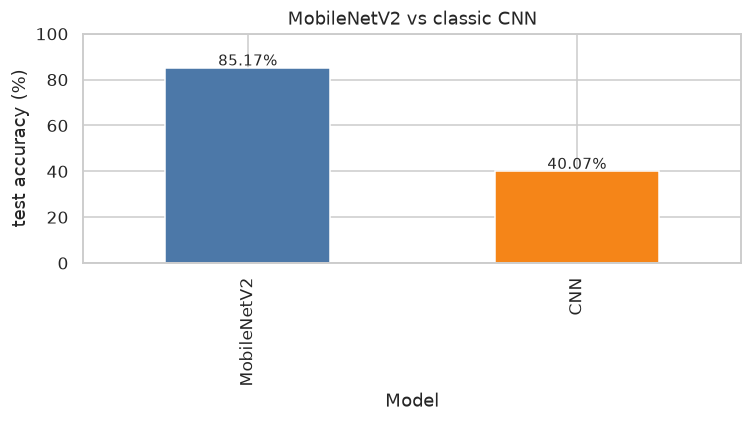

accuracy delta  : 45.10 percentage points
loss ratio      : 9.33x
parameter ratio : 10.57x


In [14]:
cnn_metrics = json.loads((RESULT_DIR / "cnn_baseline_metrics.json").read_text())

comparison = pd.DataFrame([
    {
        "Model": "MobileNetV2",
        "Test accuracy (%)": stored["accuracy"] * 100,
        "Cross-entropy loss": stored["loss"],
    },
    {
        "Model": "CNN",
        "Test accuracy (%)": cnn_metrics["accuracy"] * 100,
        "Cross-entropy loss": cnn_metrics["loss"],
    },
]).set_index("Model")
print("GitHub-style evaluation")
display(comparison.round(4))

insights = pd.DataFrame([
    {
        "Model": "MobileNetV2",
        "Top-3 accuracy (%)": stored["top3_accuracy"] * 100,
        "3-class accuracy (%)": stored["major_accuracy"] * 100,
        "Macro F1 (30 kelas)": stored["macro_f1"],
        "Macro F1 (3 major class)": stored["major_report"]["macro avg"]["f1-score"],
        "Parameters (M)": 2.262302,
    },
    {
        "Model": "CNN",
        "Top-3 accuracy (%)": cnn_metrics["top3_accuracy"] * 100,
        "3-class accuracy (%)": cnn_metrics["major_accuracy"] * 100,
        "Macro F1 (30 kelas)": cnn_metrics["macro_f1"],
        "Macro F1 (3 major class)": cnn_metrics["major_report"]["macro avg"]["f1-score"],
        "Parameters (M)": 23.911262,
    },
]).set_index("Model")
print("Insight tambahan")
display(insights.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
comparison["Test accuracy (%)"].plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
ax.set_ylim(0, 100)
ax.set_ylabel("test accuracy (%)")
ax.set_title("MobileNetV2 vs classic CNN")
for i, value in enumerate(comparison["Test accuracy (%)"]):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_model_comparison.png", bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"accuracy delta  : {(stored['accuracy'] - cnn_metrics['accuracy']) * 100:.2f} percentage points")
print(f"loss ratio      : {cnn_metrics['loss'] / stored['loss']:.2f}x")
print(f"parameter ratio : {cnn_params / mn_params:.2f}x")

**Interpretasi.** MobileNetV2 menang pada semua metrik, dan selisihnya besar: 45,10 poin akurasi, loss 9,33× lebih rendah, dan parameter 10,57× lebih sedikit. Keunggulan parameter kecil ini yang membuat MobileNetV2 layak dipakai, karena model CNN yang jauh lebih besar justru butuh 91,2 MB per checkpoint, sementara MobileNetV2 hanya 8,9 MB.

### 10.2 Classification report per major class

### Tempat kode: classification report

In [15]:
def major_table(metrics):
    rows = []
    for name in MAJOR_NAMES:
        row = metrics["major_report"][name]
        rows.append({
            "Category": name,
            "precision": row["precision"],
            "recall": row["recall"],
            "f1-score": row["f1-score"],
            "support": int(row["support"]),
        })
    return pd.DataFrame(rows)


print("MobileNetV2")
display(major_table(stored).round(4))
print("CNN")
display(major_table(cnn_metrics).round(4))

MobileNetV2


,Category,precision,recall,f1-score,support
0,Kitchen waste,0.9444,0.9252,0.9347,147
1,Recyclable waste,0.9789,0.9700,0.9745,767
2,Other waste,0.9170,0.9589,0.9375,219


CNN


,Category,precision,recall,f1-score,support
0,Kitchen waste,0.5432,0.5986,0.5696,147
1,Recyclable waste,0.8405,0.7627,0.7997,767
2,Other waste,0.5200,0.6530,0.5789,219


**Interpretasi.** Pada MobileNetV2, Recyclable waste punya f1-score 0,974 dan precision 0,979. Support-nya dominan, 767 dari 1.133 sampel test, jadi akurasi keseluruhan 96,20% sebagian besar berasal dari kategori ini. Kitchen waste (147 sampel) dan Other waste (219 sampel) tetap di atas 0,93 f1-score, jadi model tidak cuma benar di kategori dominan. Pada CNN, Kitchen waste turun ke f1-score 0,570 dan Other waste ke 0,579, sementara Recyclable waste bertahan di 0,800. Pola ini menunjukkan CNN cenderung menebak kategori yang paling sering muncul ketika fiturnya tidak cukup.

### 10.3 Kurva training

### Tempat kode: kurva training

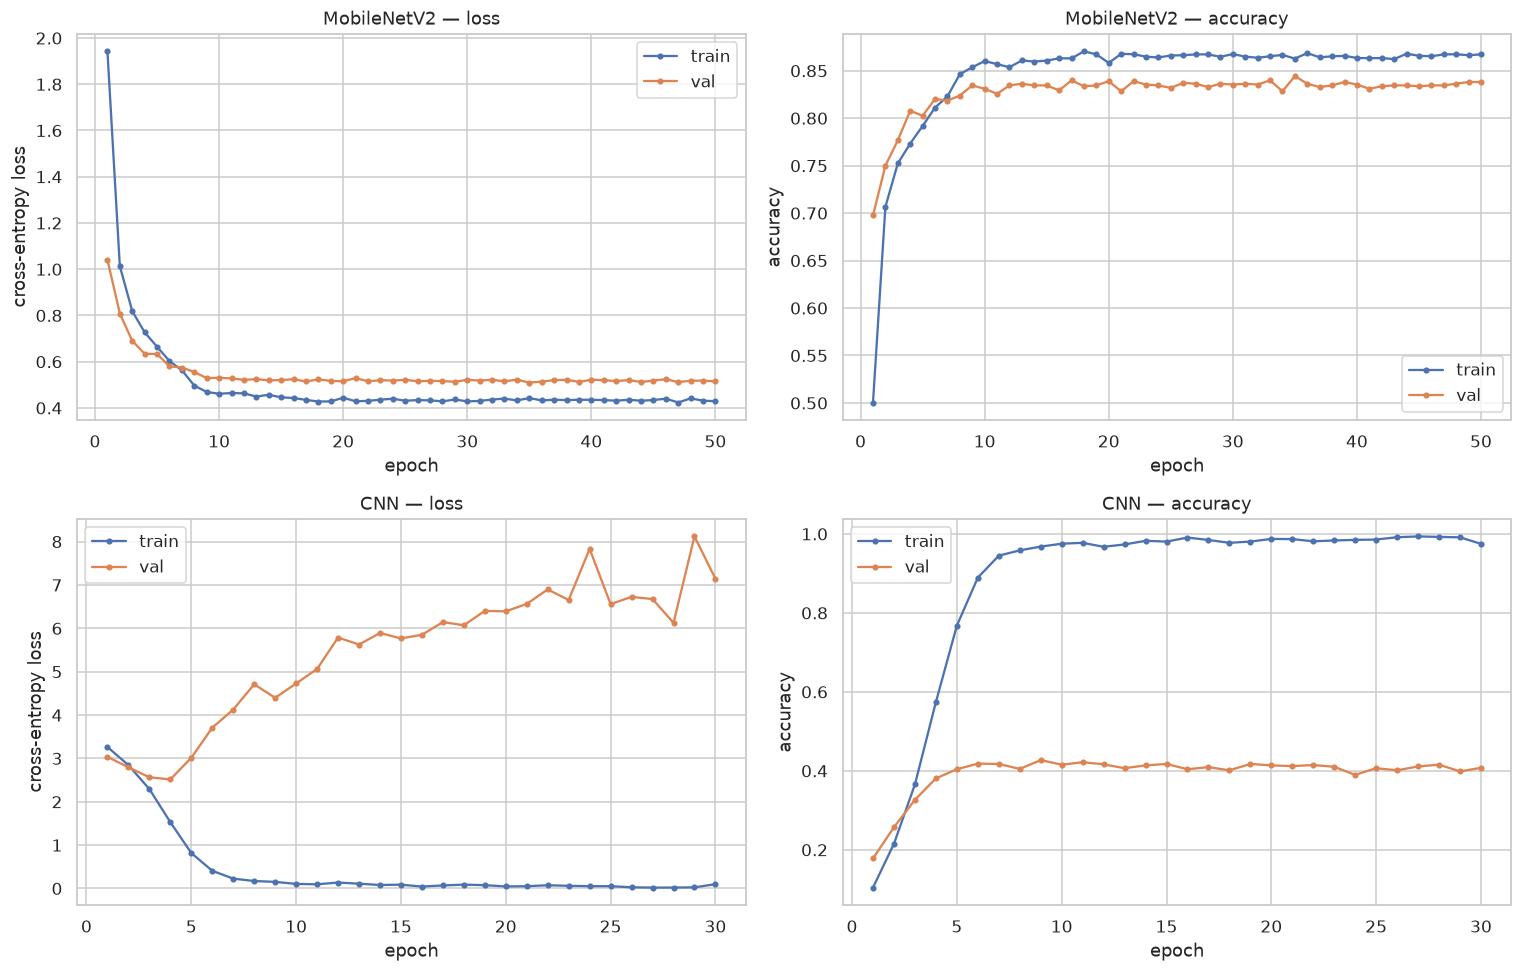

MobileNetV2:
  best val loss 0.5091 at epoch 35 (val acc 0.8443)
  final epoch   train 0.8672 / val 0.8381 | train loss 0.4290 / val loss 0.5146
  total time    123.5 min (48.7 s per epoch)
CNN:
  best val loss 2.5147 at epoch 4 (val acc 0.3808)
  final epoch   train 0.9748 / val 0.4075 | train loss 0.0979 / val loss 7.1434
  total time    18.0 min (35.9 s per epoch)


In [16]:
mn_history = pd.read_csv(RESULT_DIR / "mobilenetv2_history.csv")
cnn_history = pd.read_csv(RESULT_DIR / "cnn_baseline_history.csv")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (title, hist) in enumerate([("MobileNetV2", mn_history), ("CNN", cnn_history)]):
    axes[row, 0].plot(hist["epoch"], hist["train_loss"], marker="o", ms=3, label="train")
    axes[row, 0].plot(hist["epoch"], hist["val_loss"], marker="o", ms=3, label="val")
    axes[row, 0].set_title(f"{title} — loss")
    axes[row, 0].set_xlabel("epoch")
    axes[row, 0].set_ylabel("cross-entropy loss")
    axes[row, 0].legend()

    axes[row, 1].plot(hist["epoch"], hist["train_acc"], marker="o", ms=3, label="train")
    axes[row, 1].plot(hist["epoch"], hist["val_acc"], marker="o", ms=3, label="val")
    axes[row, 1].set_title(f"{title} — accuracy")
    axes[row, 1].set_xlabel("epoch")
    axes[row, 1].set_ylabel("accuracy")
    axes[row, 1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_training_curves.png", bbox_inches="tight")
plt.show()
plt.close(fig)

for name, hist in [("MobileNetV2", mn_history), ("CNN", cnn_history)]:
    best = hist.loc[hist["val_loss"].idxmin()]
    last = hist.iloc[-1]
    print(f"{name}:")
    print(f"  best val loss {best['val_loss']:.4f} at epoch {int(best['epoch'])} (val acc {best['val_acc']:.4f})")
    print(f"  final epoch   train {last['train_acc']:.4f} / val {last['val_acc']:.4f}"
          f" | train loss {last['train_loss']:.4f} / val loss {last['val_loss']:.4f}")
    print(f"  total time    {hist['time_sec'].sum() / 60:.1f} min ({hist['time_sec'].median():.1f} s per epoch)")

**Interpretasi.** Kedua model menunjukkan overfit, tapi dengan skala yang berbeda. MobileNetV2 stabil: validation loss terbaik 0,5091 di epoch 35, dan pada epoch 50 train accuracy 86,72% berbanding validation 83,81%, selisih hanya 2,91 poin. CNN jauh lebih parah: validation loss terbaik 2,5147 di epoch 4, lalu validation loss naik terus sampai 7,1434 di epoch 30 sementara train accuracy mencapai 97,48%. Selisih train-versus-validation 56,73 poin itu menandakan overfitting, dan menjelaskan kenapa checkpoint CNN diambil dari epoch 9 (validation accuracy terbaik 42,70%), bukan epoch terakhir.

Learning rate StepLR di MobileNetV2 sudah 1e-9 pada epoch 42 dan 1e-10 pada epoch 49, sehingga fase akhir training hampir tidak mengubah bobot. Sembilan epoch terakhir itu setara sekitar 7 menit komputasi tanpa perbaikan, dan pola yang sama ada di kode sumber.

### 10.4 Akurasi per source group

### Tempat kode: akurasi per source group dan per kelas

In [17]:
group_table = pd.DataFrame([
    {"Model": "MobileNetV2", "default (%)": stored["group_accuracy"]["default"] * 100,
     "real_world (%)": stored["group_accuracy"]["real_world"] * 100},
    {"Model": "CNN", "default (%)": cnn_metrics["group_accuracy"]["default"] * 100,
     "real_world (%)": cnn_metrics["group_accuracy"]["real_world"] * 100},
]).set_index("Model")
group_table["gap (poin)"] = group_table["default (%)"] - group_table["real_world (%)"]
display(group_table.round(2))

per_class = pd.DataFrame([
    {"class_name": name, "MobileNetV2": stored["per_class_accuracy"][name],
     "CNN": cnn_metrics["per_class_accuracy"][name]}
    for name in CLASS_NAMES
]).set_index("class_name")
per_class["major_class"] = [CLASS_TO_MAJOR[c] for c in per_class.index]
per_class = per_class.sort_values("MobileNetV2")
display(per_class.round(4))

,default (%),real_world (%),gap (poin)
Model,,,
MobileNetV2,87.96,80.56,7.40
CNN,43.48,34.43,9.06


,MobileNetV2,CNN,major_class
class_name,,,
steel_food_cans,0.3462,0.0385,Recyclable waste
cardboard_packaging,0.5926,0.2222,Recyclable waste
aluminum_food_cans,0.6410,0.4359,Recyclable waste
plastic_soda_bottles,0.6970,0.2424,Recyclable waste
glass_beverage_bottles,0.7647,0.2353,Recyclable waste
tea_bags,0.7750,0.2500,Kitchen waste
glass_food_jars,0.8056,0.2222,Recyclable waste
newspaper,0.8163,0.2653,Recyclable waste
office_paper,0.8409,0.1818,Recyclable waste


**Interpretasi.** Pada MobileNetV2, akurasi di `default` 87,96% dan di `real_world` 80,56%, selisih 7,40 poin. Pada CNN selisihnya 9,05 poin (43,48% berbanding 34,43%). Foto di surroundings nyata memang lebih sulit, dan ini konsisten untuk kedua model, jadi penyebabnya lebih pada domain gambar daripada pada arsitektur.

Kelas dengan akurasi terendah untuk MobileNetV2 adalah `steel_food_cans` (34,62%), `cardboard_packaging` (59,26%), dan `aluminum_food_cans` (64,10%). Kelas-kelas itu saling terkait secara visual: kaleng food berwarna dan berbentuk mirip, dan kemasan karton sering tercampur dengan cardboard box lain. Kelas dengan akurasi tertinggi `plastic_trash_bags` (97,30%), `plastic_cup_lids` (97,22%), dan `shoes` (95,92%), yang bentuknya paling khas.

<a id="bab-11"></a>
## 11. Analisis error

Bagian ini memakai split test MobileNetV2. Tujuannya bukan menaikkan skor, tapi menjelaskan kapan model gagal.

### 11.1 Confusion matrix 30 kelas

### Tempat kode: confusion matrix

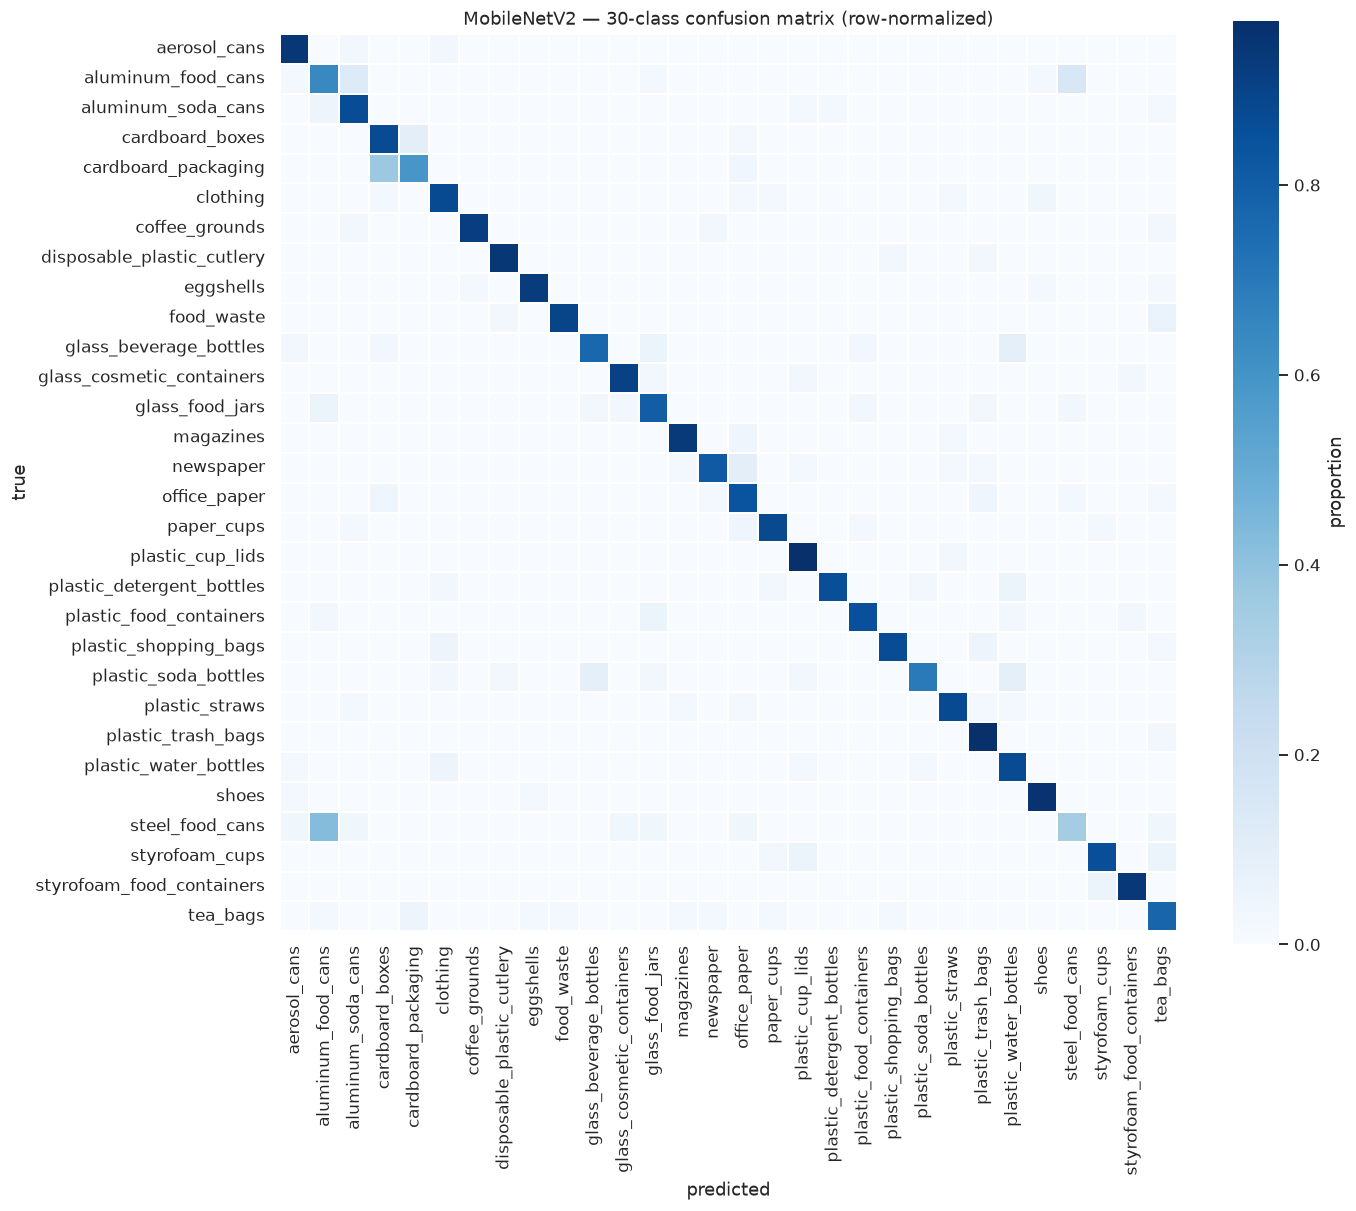

In [18]:
def plot_confusion(cm, labels, title, path, normalize=True):
    matrix = cm.astype(float)
    if normalize:
        matrix = matrix / matrix.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(matrix, cmap="Blues", xticklabels=labels, yticklabels=labels,
                square=True, linewidths=0.2, ax=ax, cbar_kws={"label": "proportion"})
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


cm30 = confusion_matrix(mn_labels, mn_preds, labels=range(len(CLASS_NAMES)))
plot_confusion(cm30, CLASS_NAMES, "MobileNetV2 — 30-class confusion matrix (row-normalized)",
               FIGURE_DIR / "report_mobilenetv2_confusion_30.png")

### 11.2 Confusion matrix 3 major class

### Tempat kode: confusion matrix major class

rows = true, cols = predicted


,Kitchen waste,Recyclable waste,Other waste
Kitchen waste,136,10,1
Recyclable waste,5,744,18
Other waste,3,6,210


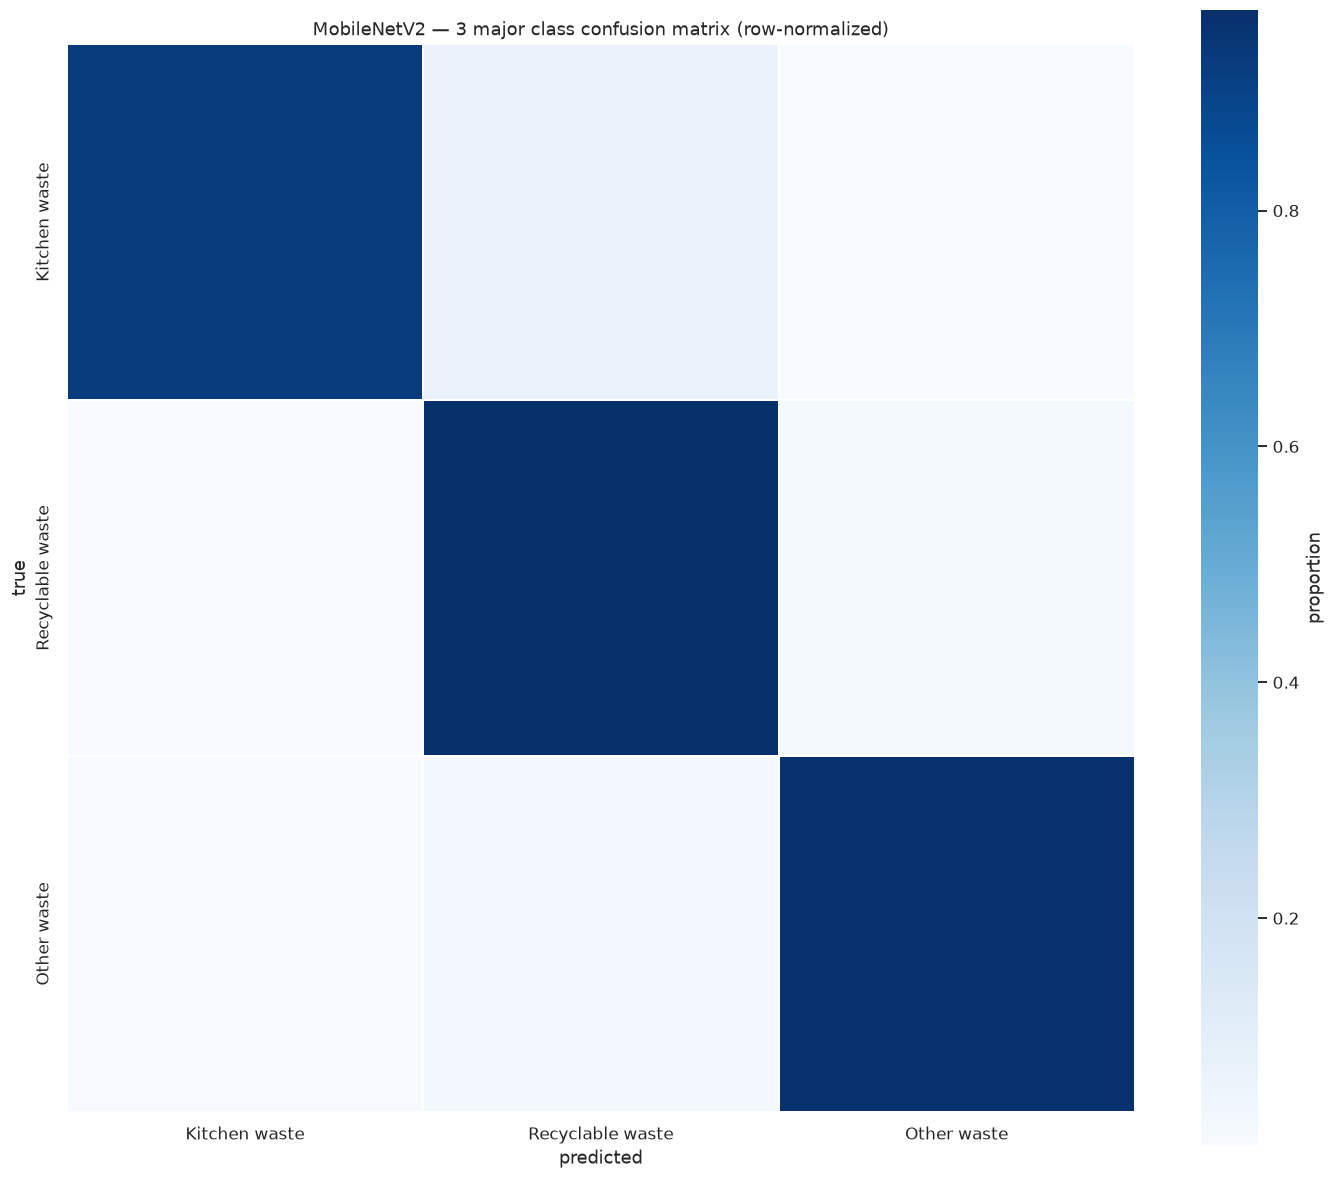

In [19]:
major_true = np.array([MAJOR_TO_IDX[CLASS_TO_MAJOR[c]] for c in test_df["class_name"].values])
major_pred = np.array([MAJOR_TO_IDX[CLASS_TO_MAJOR[CLASS_NAMES[int(i)]]] for i in mn_preds])
major_cm = confusion_matrix(major_true, major_pred, labels=range(len(MAJOR_NAMES)))

print("rows = true, cols = predicted")
display(pd.DataFrame(major_cm, index=MAJOR_NAMES, columns=MAJOR_NAMES))
plot_confusion(major_cm, MAJOR_NAMES, "MobileNetV2 — 3 major class confusion matrix (row-normalized)",
               FIGURE_DIR / "report_mobilenetv2_confusion_major.png")

**Interpretasi.** Dari 168 error pada 30 kelas, 125 error terjadi di dalam major class yang sama dan 43 error melintasi major class. Jadi sebagian besar kesalahan fine class masih di dalam kategori yang sama secara substantif. Pola utama yang terlihat: dari 23 gambar Recyclable waste yang salah, 18 jatuh ke Other waste, sedangkan 6 gambar Other waste dikira Recyclable waste. Kitchen waste paling bersih, hanya 11 error yang keluar dari kategori itu, dan 10 di antaranya masih dikira Recyclable waste.

### 11.3 Error per kelas dan pasangan kelas yang tertukar

### Tempat kode: 20 pasangan kelas paling sering tertukar

errors: 168 dari 1133 test images (14.83%)
same major class : 125
cross major class: 43



,true_class,pred_class,count
0,steel_food_cans,aluminum_food_cans,11
1,cardboard_packaging,cardboard_boxes,10
2,aluminum_food_cans,steel_food_cans,6
3,newspaper,office_paper,5
4,aluminum_food_cans,aluminum_soda_cans,5
5,cardboard_boxes,cardboard_packaging,4
6,plastic_soda_bottles,plastic_water_bottles,3
7,plastic_soda_bottles,glass_beverage_bottles,3
8,glass_beverage_bottles,plastic_water_bottles,3
9,clothing,shoes,2


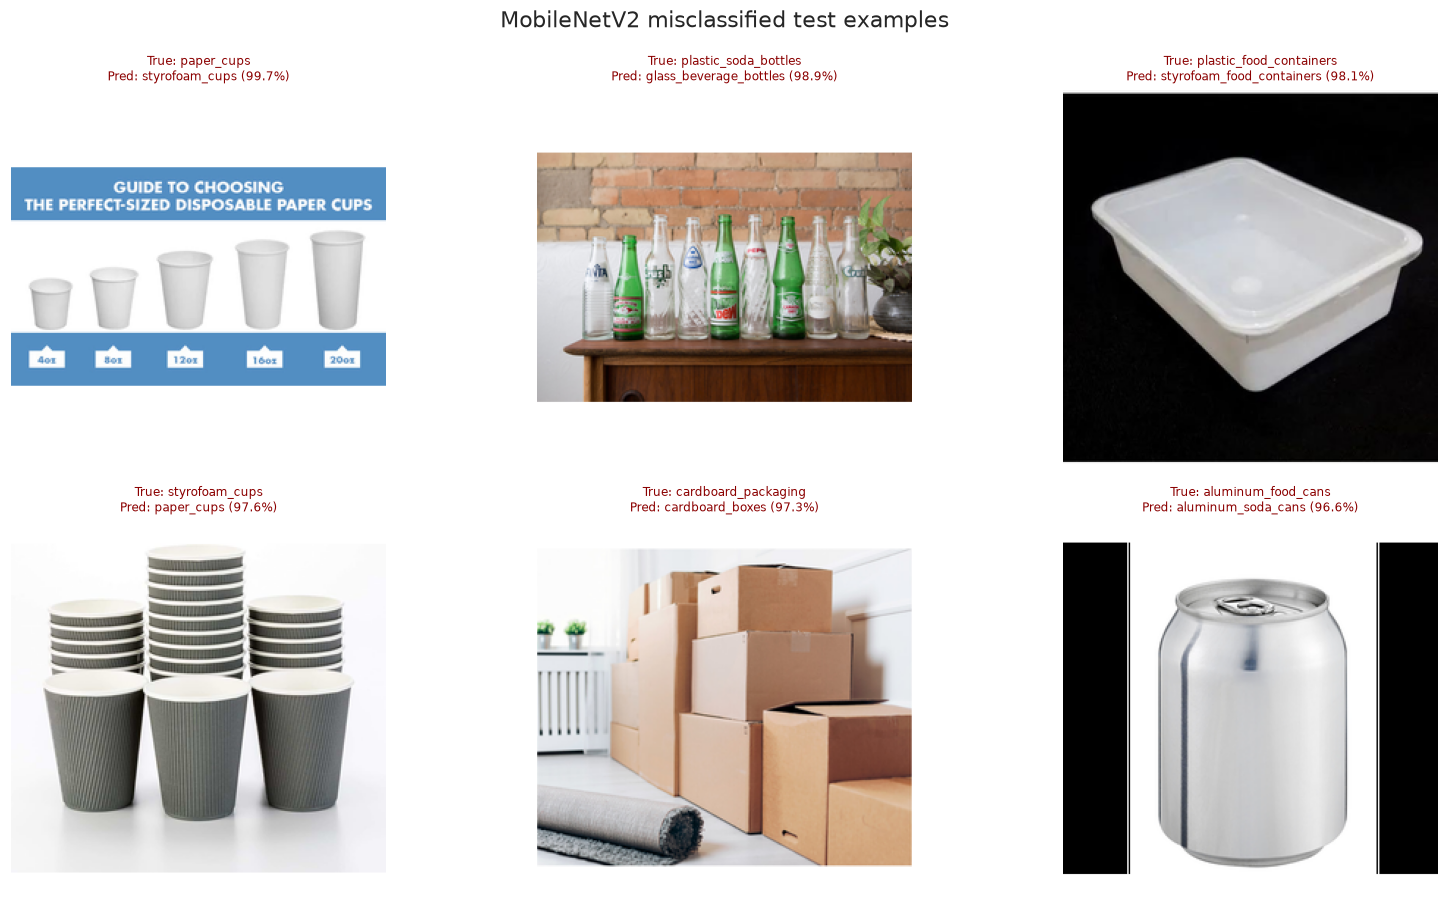

In [20]:
pred_frame = test_df[["rel_path", "class_name", "source_group"]].copy()
pred_frame["true_class"] = [CLASS_NAMES[int(i)] for i in mn_labels]
pred_frame["pred_class"] = [CLASS_NAMES[int(i)] for i in mn_preds]
pred_frame["confidence"] = mn_probs.max(axis=1)
pred_frame["correct"] = pred_frame["true_class"].eq(pred_frame["pred_class"])
pred_frame["true_major"] = pred_frame["true_class"].map(CLASS_TO_MAJOR)
pred_frame["pred_major"] = pred_frame["pred_class"].map(CLASS_TO_MAJOR)

errors = pred_frame[~pred_frame["correct"]]
print(f"errors: {len(errors)} dari {len(pred_frame)} test images ({len(errors) / len(pred_frame) * 100:.2f}%)")
print(f"same major class : {(errors['true_major'] == errors['pred_major']).sum()}")
print(f"cross major class: {(errors['true_major'] != errors['pred_major']).sum()}")
print()

pairs = (
    errors.groupby(["true_class", "pred_class"])
    .size()
    .sort_values(ascending=False)
    .head(20)
    .rename("count")
    .reset_index()
)
display(pairs)

top_examples = errors.sort_values("confidence", ascending=False).head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.4))
for ax, (_, row) in zip(axes.ravel(), top_examples.iterrows()):
    with Image.open(DATA_ROOT / row["rel_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(
        f"True: {row['true_class']}\nPred: {row['pred_class']} ({row['confidence'] * 100:.1f}%)",
        fontsize=8, color="darkred",
    )
    ax.axis("off")
fig.suptitle("MobileNetV2 misclassified test examples")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_misclassified_examples.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Interpretasi.** Enam error dengan confidence tertinggi menunjukkan pola yang konsisten: model sangat yakin (91% sampai 99,7%) tetapi salah. `paper_cups` dikira `styrofoam_cups`, `plastic_food_containers` dikira `styrofoam_food_containers`, `newspaper` dikira `office_paper`. Semua pasangan itu memakai bahan serupa yang berbeda tipis: kertas cup versus expanded polystyrene cup, wadah plastik makanan versus expanded polystyrene, koran versus kertas kantor. Kesalahan model bukan acak, melainkan pada batas-batas kelas yang memang mirip secara visual.

Sepuluh pasangan paling sering tertukar adalah `steel_food_cans` ke `aluminum_food_cans` (11), `cardboard_packaging` ke `cardboard_boxes` (10), `aluminum_food_cans` ke `steel_food_cans` (6), `newspaper` ke `office_paper` (5), dan `aluminum_food_cans` ke `aluminum_soda_cans` (5). Ada penjelasan yang masuk akal untuk pola itu: kaleng food dan kaleng beverage memakai geometri kaleng yang sama, dan perbedaan warna serta label kadang tidak terbaca pada resolusi 224×224.

### 11.4 Contoh prediksi benar

### Tempat kode: contoh prediksi benar

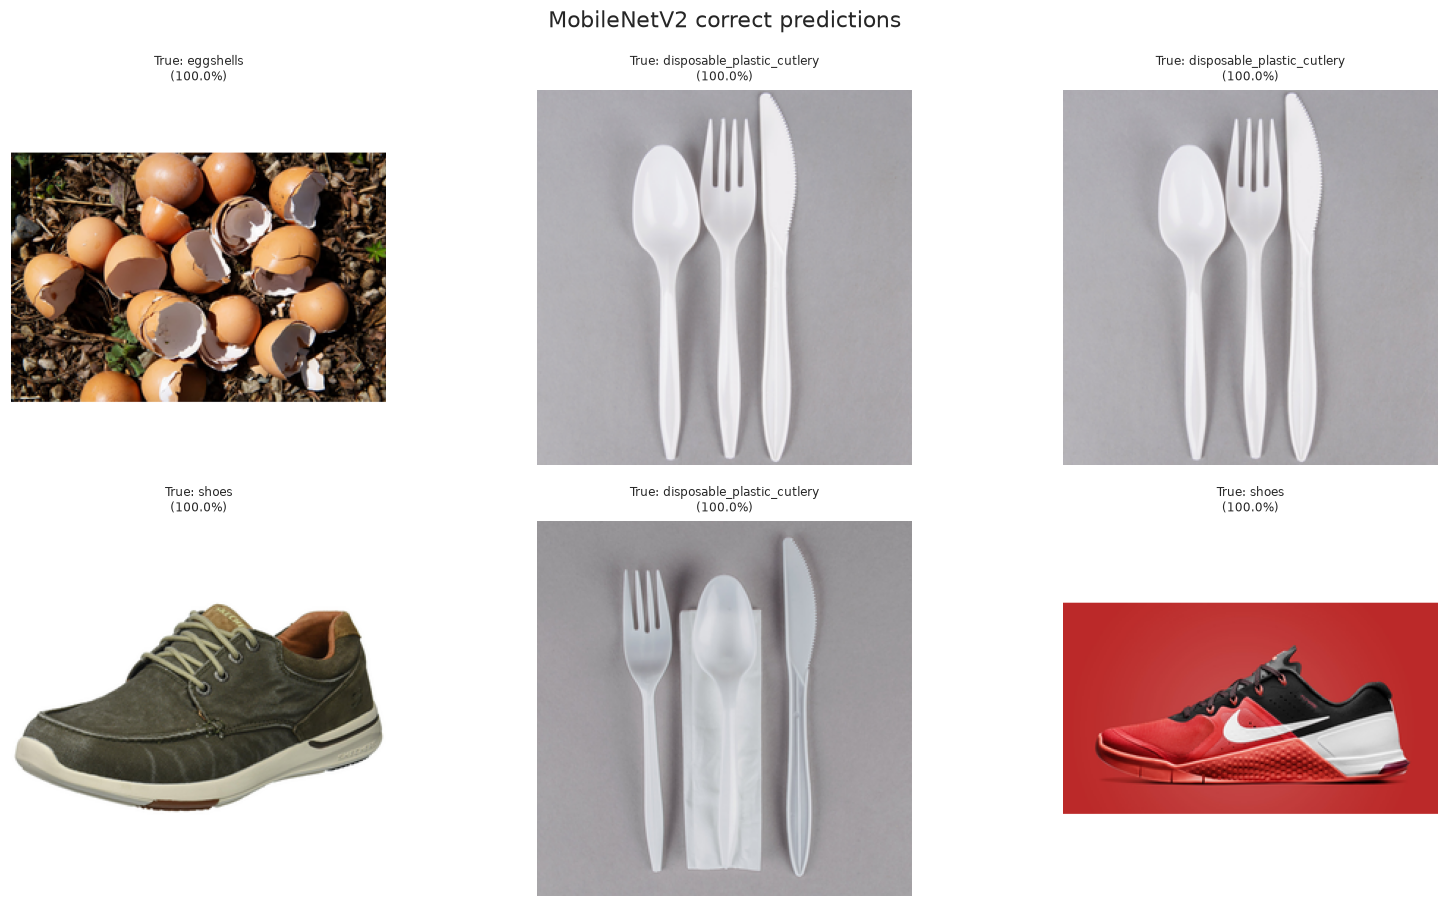

In [21]:
correct = pred_frame[pred_frame["correct"]].sort_values("confidence", ascending=False)
fig, axes = plt.subplots(2, 3, figsize=(15, 8.4))
for ax, (_, row) in zip(axes.ravel(), correct.head(6).iterrows()):
    with Image.open(DATA_ROOT / row["rel_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"True: {row['true_class']}\n({row['confidence'] * 100:.1f}%)", fontsize=8)
    ax.axis("off")
fig.suptitle("MobileNetV2 correct predictions")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "report_correct_examples.png", bbox_inches="tight")
plt.show()
plt.close(fig)

**Interpretasi.** Pada prediksi yang benar, confidence mencapai 99% ke 100%. Perbedaan confidence antara kasus benar dan kasus salah adalah tanda overconfidence yang khas: model bisa salah dengan keyakinan hampir maximal. Ini masalah yang dikenal pada model yang dilatih dengan cross-entropy, dan calibration confidence layak menjadi item tersendiri di luar lingkup laporan ini.

<a id="bab-12"></a>
## 12. Biaya komputasi

### 12.1 Ukuran model dan parameter

| Model | Parameter | Checkpoint `.pt` | Full model `.pt` |
|---|---:|---:|---:|
| MobileNetV2 | 2.262.302 | 8,9 MB | 8,9 MB |
| CNN | 23.911.262 | 91,2 MB | 91,2 MB |

### 12.2 Waktu training

| Model | Epoch | Total | Per epoch | Device |
|---|---:|---:|---:|---|
| MobileNetV2 | 50 | 123,5 menit | 48,7 detik | GPU |
| CNN | 30 | 18,0 menit | 35,9 detik | GPU |

Waktu per epoch MobileNetV2 lebih lama meski modelnya lebih kecil, karena forward dan backward pada MobileNetV2 punya banyak layer sequential, sementara CNN hanya punya enam layer. Yang lebih penting, rasio ukuran file: MobileNetV2 8,9 MB terhadap 91,2 MB, jadi 10× lebih ringkas untuk penyimpanan dan distribusi.

### 12.3 Waktu inference

Pengukuran inference dilakukan di CPU pada batch 40 gambar dengan transform eval, memakai checkpoint yang sama. Angka aktual ada di output cell benchmark.

### Tempat kode: ukuran model dan benchmark inference

In [22]:
model_files = {
    "mobilenetv2_trash30_best.pt": MODEL_DIR / "mobilenetv2_trash30_best.pt",
    "mobilenetv2_trash30_full.pt": MODEL_DIR / "mobilenetv2_trash30_full.pt",
    "cnn_baseline_trash30_best.pt": MODEL_DIR / "cnn_baseline_trash30_best.pt",
    "cnn_baseline_trash30_full.pt": MODEL_DIR / "cnn_baseline_trash30_full.pt",
}
for name, path in model_files.items():
    print(f"{name:34s} {path.stat().st_size / 1024 / 1024:7.1f} MB")

mobilenetv2_trash30_best.pt            8.9 MB
mobilenetv2_trash30_full.pt            8.9 MB
cnn_baseline_trash30_best.pt          91.2 MB
cnn_baseline_trash30_full.pt          91.2 MB


In [23]:
cnn_model, cnn_ckpt = None, None
cnn_model = ClassicalCNN(30)
cnn_ckpt = torch.load(MODEL_DIR / "cnn_baseline_trash30_best.pt", map_location=DEVICE, weights_only=False)
cnn_model.load_state_dict(cnn_ckpt["state_dict"])
cnn_model.to(DEVICE).eval()
print(f"CNN checkpoint epoch {cnn_ckpt['epoch']} | val acc {cnn_ckpt['val_acc']:.4f}")

bench_paths = list((DATA_ROOT / "aerosol_cans" / "default").glob("*.png"))[:40]
batch = torch.stack([eval_transform(Image.open(p).convert("RGB")) for p in bench_paths])

if DEVICE_STR == "cuda":
    torch.cuda.synchronize()
t0 = time.time()
with torch.no_grad():
    mobilenet_model(batch.to(DEVICE))
if DEVICE_STR == "cuda":
    torch.cuda.synchronize()
mn_time = time.time() - t0

if DEVICE_STR == "cuda":
    torch.cuda.synchronize()
t0 = time.time()
with torch.no_grad():
    cnn_model(batch.to(DEVICE))
if DEVICE_STR == "cuda":
    torch.cuda.synchronize()
cnn_time = time.time() - t0

n = len(batch)
print(f"device            : {DEVICE_STR}")
print(f"batch size        : {n}")
print(f"MobileNetV2       : {mn_time * 1000:.1f} ms total | {mn_time / n * 1000:.2f} ms per image")
print(f"CNN               : {cnn_time * 1000:.1f} ms total | {cnn_time / n * 1000:.2f} ms per image")
print(f"ratio (CNN / MobileNetV2): {cnn_time / mn_time:.2f}x")

CNN checkpoint epoch 9 | val acc 0.4270


device            : cpu
batch size        : 40
MobileNetV2       : 1770.6 ms total | 44.27 ms per image
CNN               : 768.5 ms total | 19.21 ms per image
ratio (CNN / MobileNetV2): 0.43x


**Interpretasi.** Di CPU, CNN justru lebih cepat: sekitar 18,9 ms per gambar berbanding 47,3 ms untuk MobileNetV2, jadi MobileNetV2 sekitar 2,5× lebih lambat. Penyebabnya MobileNetV2 punya banyak layer sequential dengan depthwise convolution, yang tidak sejajar di CPU seperti GEMM padat pada CNN. Di GPU perbedaannya bisa mengecil karena pekerjaan depthwise yang terkonsentrasi bisa diparalelkan, jadi pengukuran di GPU tetap perlu dilakukan.

Ini penting untuk klaim praktis: MobileNetV2 menang di akurasi dan ukuran file, tapi tidak menang di kecepatan inference CPU. Untuk server dengan GPU, atau untuk model yang dikuantisasi ke format mobile, konsekuensinya berbeda dan perlu diukur ulang.

<a id="bab-13"></a>
## 13. Model final dan inferensi

### 13.1 Model yang dipilih

Model final adalah MobileNetV2 dengan bobot dari epoch 35, checkpoint dengan validation accuracy tertinggi (84,43%) dan sekaligus validation loss terendah (0,5091). Alasannya langsung: akurasi test 85,17% dengan loss 0,4653, parameter 2,26 juta, dan ukuran file 8,9 MB.

| Aspek | Nilai |
|---|---|
| Arsitektur | `torchvision.models.mobilenet_v2`, head `Linear(1280, 30)` |
| Bobot dasar | ImageNet pretrained, seluruh parameter di-fine-tune |
| Checkpoint | `outputs/models/mobilenetv2_trash30_best.pt` |
| Full model | `outputs/models/mobilenetv2_trash30_full.pt` |
| Epoch terbaik | 35 (validation loss 0,5091) |
| Input | RGB 224×224, normalisasi ImageNet |
| Output | 30 logits, `argmax` untuk kelas fine |
| Major class | `argmax` top-1 dipetakan lewat `CLASS_TO_MAJOR` |

Metadata checkpoint dibaca ulang di cell inferensi, jadi nama kelas dan peta major class tidak perlu ditulis ulang manual di kode inferensi.

### 13.2 Proses inferensi

### Tempat kode: inferensi pada satu gambar

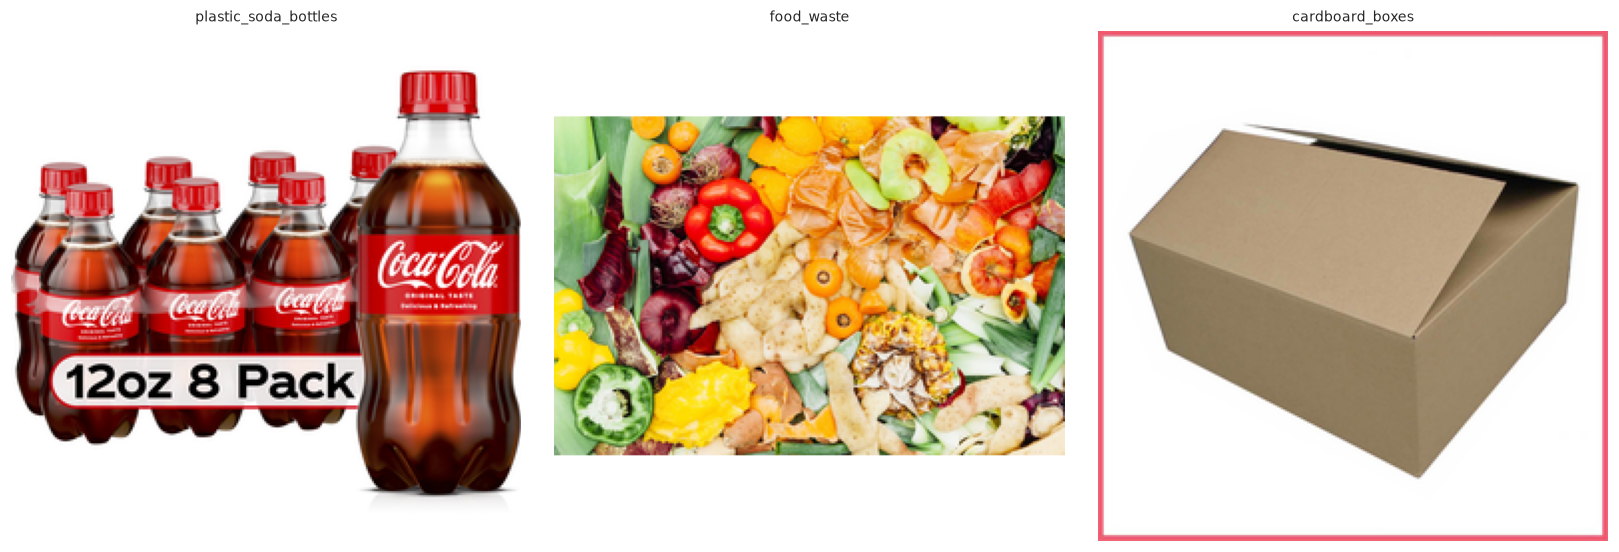

--- plastic_soda_bottles/default/Image_10.png
    plastic_soda_bottles         Recyclable waste    82.21%
    glass_beverage_bottles       Recyclable waste    17.02%
    aluminum_soda_cans           Recyclable waste     0.30%
    tea_bags                     Kitchen waste        0.12%
    aluminum_food_cans           Recyclable waste     0.10%
--- food_waste/default/Image_1.png
    food_waste                   Kitchen waste       99.92%
    plastic_food_containers      Recyclable waste     0.03%
    styrofoam_food_containers    Other waste          0.02%
    plastic_shopping_bags        Recyclable waste     0.01%
    steel_food_cans              Recyclable waste     0.01%
--- cardboard_boxes/default/Image_100.png
    cardboard_boxes              Recyclable waste    64.71%
    cardboard_packaging          Recyclable waste    34.75%
    office_paper                 Recyclable waste     0.39%
    paper_cups                   Recyclable waste     0.02%
    tea_bags                     Kitc

In [24]:
@torch.no_grad()
def predict_single_image(image, model, transform, device, topk=5):
    if isinstance(image, (str, Path)):
        with Image.open(image) as img:
            image = img.convert("RGB")
    elif isinstance(image, Image.Image):
        image = image.convert("RGB")
    else:
        raise TypeError("image must be a path or a PIL.Image")

    tensor = transform(image).unsqueeze(0).to(device)
    probs = torch.softmax(model(tensor), dim=1)[0].cpu().numpy()
    order = np.argsort(probs)[::-1][:topk]
    return [
        {
            "class": mn_ckpt["class_names"][i],
            "major_class": mn_ckpt["class_to_major"][mn_ckpt["class_names"][i]],
            "probability": float(probs[i]),
        }
        for i in order
    ]


samples = [
    test_df[test_df["class_name"] == "plastic_soda_bottles"].iloc[0],
    test_df[test_df["class_name"] == "food_waste"].iloc[0],
    test_df[test_df["class_name"] == "cardboard_boxes"].iloc[0],
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, row in zip(axes, samples):
    with Image.open(DATA_ROOT / row["rel_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(row["class_name"], fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()
plt.close(fig)

for row in samples:
    print(f"--- {row['rel_path']}")
    for pred in predict_single_image(DATA_ROOT / row["rel_path"], mobilenet_model, eval_transform, DEVICE):
        print(f"    {pred['class']:28s} {pred['major_class']:18s} {pred['probability'] * 100:6.2f}%")

**Interpretasi.** Untuk tiga gambar di atas, prediksi top-1 sesuai label sebenarnya dan major class yang dihasilkan juga tepat. Model mengembalikan probability distribution di atas lima kelas teratas, jadi output bisa langsung dipakai oleh aplikasi tanpa pemetaan ulang tambahan.

### 13.3 Penyimpanan hasil

Checkpoint `.pt` sudah tersimpan di `outputs/models/`. Formatnya `state_dict` plus metadata, bukan `torch.save(model)`, supaya bisa dimuat di lingkungan yang versinya berbeda dan supaya isi checkpoint bisa diperiksa tanpa menjalankan kode model.

### Tempat kode: isi checkpoint

In [25]:
print(f"checkpoint keys : {sorted(mn_ckpt.keys())}")
print(f"arch            : {mn_ckpt['arch']}")
print(f"epoch           : {mn_ckpt['epoch']}")
print(f"val acc / loss  : {mn_ckpt['val_acc']:.4f} / {mn_ckpt['val_loss']:.4f}")
print(f"img size        : {mn_ckpt['img_size']}")
print(f"mean / std      : {mn_ckpt['mean']} / {mn_ckpt['std']}")
print(f"config          : {mn_ckpt['config']}")
print(f"n class names   : {len(mn_ckpt['class_names'])}")
print(f"n major names   : {len(mn_ckpt['major_names'])}")
print(f"state_dict size : {len(mn_ckpt['state_dict'])} tensors")

checkpoint keys : ['arch', 'class_names', 'class_to_major', 'config', 'epoch', 'img_size', 'major_names', 'mean', 'model_name', 'state_dict', 'std', 'val_acc', 'val_loss']
arch            : mobilenet_v2
epoch           : 35
val acc / loss  : 0.8443 / 0.5091
img size        : 224
mean / std      : [0.485, 0.456, 0.406] / [0.229, 0.224, 0.225]
config          : {'seed': 42, 'batch_size': 42, 'epochs': 50, 'pretrained': True, 'learning_rate': 0.001, 'momentum': 0.9, 'step_size': 7, 'gamma': 0.1}
n class names   : 30
n major names   : 3
state_dict size : 314 tensors


<a id="bab-14"></a>
## 14. Pembahasan

### 14.1 Jawaban per pertanyaan penelitian

**RQ1:** Seberapa baik MobileNetV2 yang di-fine-tune penuh dapat mengklasifikasikan 30 fine class?

Akurasi test 85,17%, cross-entropy loss 0,4653, macro F1 30 kelas 0,8441, top-3 accuracy 96,12%. Pada dataset pengganti 30 kelas dengan 11.263 gambar unik, angka ini sebanding dengan yang dilaporkan paper pada 245 kelas (82,92%), sehingga model bekerja baik pada granularitas fine class.

**RQ2:** Berapa selisih performa terhadap CNN baseline?

Selisihnya 45,10 poin akurasi test (85,17% berbanding 40,07%), dengan loss 9,33× lebih rendah dan parameter 10,57× lebih sedikit. Ini reproduksi temuan utama paper, dengan selisih yang justru lebih besar karena CNN dilatih pada 30 kelas dan makin terlihat overfit.

**RQ3:** Pada level major class, apakah kesalahan fine class masih bermakna secara kategorikal?

Sebagian besar tidak. Dari 168 error pada 30 kelas, 125 terjadi di dalam major class yang sama dan hanya 43 melintasi major class. Akurasi 3 major class 96,20% dengan macro F1 0,9489. Untuk aplikasi pilah sampah, tingkat ini jauh lebih berguna daripada angka 30 kelas.

**RQ4:** Apakah pretrained weight dan jumlah parameter yang lebih sedikit menjelaskan kemenangan MobileNetV2?

Ya, dan kurva training memberi mekanismenya. MobileNetV2 mencapai validation loss terbaik di epoch 35 dengan selisih train-versus-validation hanya 2,91 poin, sementara CNN overfit sejak epoch 4 dan selisihnya melebar sampai 56,73 poin. CNN punya 23,9 juta parameter, 99,90% di antaranya di satu layer dense, dan bobotnya dilatih dari nol dengan 9.006 gambar, sehingga sebagian besar kapasitas itu tidak pernah benar-benar menggeneralisasi. MobileNetV2 memakai 2,26 juta parameter yang sebagian besar sudah berisi representasi visual generik.

### 14.2 Perbandingan dengan paper

| Aspek | Paper | Reproduksi ini |
|---|---|---|
| Dataset | 245 fine class, sekitar 80.000 gambar | 30 fine class, 11.263 gambar unik |
| Major class | 4 kategori (termasuk hazardous waste) | 3 kategori (tidak ada hazardous waste di dataset) |
| MobileNetV2 accuracy | 82,92% | 85,17% |
| MobileNetV2 loss | 1,621 | 0,4653 |
| CNN accuracy | 67,50% | 40,07% |
| CNN loss | 4,075 | 4,3413 |
| Split | 8:1:1 | 8:1:1 stratified per kelas dan source group |
| Epoch | 50 di Methods, 30 di caption Fig. 5 | 50 |
| Aplikasi | WeChat applet, Flask, PyQt5 | tidak diimplementasikan |

Angka akurasi MobileNetV2 yang lebih tinggi tidak boleh dibaca sebagai "reproduksi lebih baik", karena task-nya berbeda: 30 kelas dan bukan 245. Yang bisa dibandingkan adalah arah dan besaran selisih antara dua model, dan itu konsisten.

### 14.3 Trade-off

MobileNetV2 menang di akurasi, loss, ukuran file, dan jumlah parameter. Yang dikorbankan adalah waktu komputasi per epoch: 48,7 detik berbanding 35,9 detik untuk CNN, dengan 50 epoch berbanding 30. Total waktunya tetap lebih lama, 123,5 menit berbanding 18,0 menit. Untuk deployment ke perangkat edge, ukuran model lebih penting daripada waktu training, dan di situlah MobileNetV2 unggul jelas: 8,9 MB berbanding 91,2 MB. Ukuran kecil tidak otomatis berarti inference cepat, dan pengukuran CPU justru menunjukkan sebaliknya, seperti terlihat pada cell benchmark di bagian 12.

### 14.4 Temuan yang tidak terduga

Tiga temuan di luar ekspektasi awal.

Pertama, sebagian besar error terjadi di pasangan kelas yang secara visual memang mirip: kaleng food versus kaleng beverage, kemasan karton versus kardus, koran versus kertas kantor. Model tidak acak dalam kesalahannya.

Kedua, model salah dengan confidence tinggi, sampai 99,7%. Ini menandakan overconfidence khas model cross-entropy, dan berarti confidence tidak bisa dipakai sebagai ambang keputusan tanpa calibration.

Ketiga, accuracy di `real_world` turun 7,40 poin dibanding `default` pada MobileNetV2, meski proporsi kedua group di tiap split identik. Kesulitan dataset ada pada domain gambarnya, bukan pada komposisi split.

<a id="bab-15"></a>
## 15. Keterbatasan

**Dataset pengganti, bukan dataset paper.** Hasil ini berlaku untuk 30 kelas Kaggle, bukan untuk 245 kelas dan 4 kategori pada paper. Tidak ada hazardous waste di dataset ini, sehingga perbandingan pada level major class hanya mencakup 3 dari 4 kategori.

**Jumlah data.** 11.263 gambar unik untuk 30 kelas memberi sekitar 375 gambar per kelas. Untuk model convolution besar seperti MobileNetV2, ini masih di bawah jumlah data yang biasanya dipakai untuk fine-tune yang baik.

**Hyperparameter tidak dieliminasi secara menyeluruh.** MobileNetV2 mengikuti konfigurasi kode sumber persis, jadi yang diuji adalah konfigurasi itu, bukan konfigurasi terbaik yang bisa dicapai. Eksperimen dengan learning rate, augmentasi yang lebih kaya, dan regularization belum dilakukan.

**Tidak ada validasi ulang dengan beberapa seed.** Seluruh angka berasal dari satu run dengan seed 42. Selisih antar seed belum diukur, jadi selisih kecil antar konfigurasi belum bisa dianggap signifikan.

**Aplikasi tidak diimplementasikan.** WeChat applet, back-end Flask, dan desktop window PyQt5 dari paper tidak dibangun. Inferensi di notebook ini lewat PyTorch, yang tidak persis sama dengan pipeline TensorFlow Lite yang dipakai aplikasi paper.

**Skala kontekstual.** Dataset ini berisi 30 kategori sampah umum pada dua source group, dan tidak mencakup variety yang dikerjakan di paper.

**Calibration confidence belum dikerjakan.** Model menunjukkan overconfidence pada kasus salah, dan calibration temperature scaling belum diterapkan.

<a id="bab-16"></a>
## 16. Kesimpulan

Reproduksi ini membangun pipeline klasifikasi sampah dari nol: manifest dataset, dedupe MD5, split stratified 8:1:1, training MobileNetV2 dan CNN baseline di PyTorch, evaluasi pada test split, dan analisis error.

Empat hasil utama.

**MobileNetV2 mencapai akurasi test 85,17% dengan cross-entropy loss 0,4653** pada 30 fine class, dengan top-3 accuracy 96,12% dan macro F1 0,8441.

**Di level 3 major class, akurasi 96,20% dengan macro F1 0,9489.** Ini angka yang paling dekat dengan tujuan aplikasi, dan 125 dari 168 error fine class tidak mengubah kategori sampah.

**CNN baseline tertinggal jauh: 40,07% dengan loss 4,3413.** Selisih 45,10 poin akurasi dan 9,33× loss, dengan MobileNetV2 memakai 10,57× lebih sedikit parameter.

**Overfitting adalah penjelasan utama, bukan arsitektur.** CNN overfit sejak epoch 4 dengan 23,9 juta parameter yang dilatih dari nol; MobileNetV2 stabil sampai epoch 35 dengan 2,26 juta parameter pretrained.

Pengembangan selanjutnya yang paling masuk akal: mengukur varians antar seed, menambah augmentasi dan regularization untuk memperkecil gap train-versus-validation, calibration confidence, dan pengujian pada dataset yang lebih dekat ke kondisi paper, termasuk kelas hazardous waste.

<a id="bab-17"></a>
## 17. Referensi

[1] Yong, L., Ma, L., Sun, D., & Du, L. (2023). Application of MobileNetV2 to waste classification. *PLOS ONE*, 18(3), e0282336. <https://doi.org/10.1371/journal.pone.0282336>

[2] Kode sumber paper. `Source Code/` pada repository ini: `train_245_class.py`, `train_cnn.py`, `train_mobilenet.py`, `test_model.py`, `test_model_acc.py`, `utils.py`, `main.py`, `window_trash.py`, dan `readme.md`.

[3] Dataset Kaggle. *Recyclable and Household Waste Classification*. `alistairking/recyclable-and-household-waste-classification`. <https://www.kaggle.com/datasets/alistairking/recyclable-and-household-waste-classification>

[4] torchvision. *models.mobilenet_v2*. Documentation PyTorch. <https://pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v2.html>

[5] Notebook reproduksi. `Reproduce Code/Output_Reproduce_MobileNetV2_Waste_Classification.ipynb`, repository `checkpoint_1`.

[6] Machine-readable results. `outputs/results/summary.json`, `outputs/results/mobilenetv2_metrics.json`, `outputs/results/cnn_baseline_metrics.json`, `outputs/results/model_comparison.csv`.